# Diabetes Risk Prediction — CDC NHANES Clinical & Survey Data

**Objective:** Build an end-to-end machine learning pipeline that classifies U.S. adults as Normal, Prediabetes, or Diabetes using easily obtained measurements (demographics, body measures, blood pressure, cholesterol, lifestyle, and family history), and identify which of these factors the model relies on most.

**Dataset:** CDC National Health and Nutrition Examination Survey (NHANES), cycles 2011–2018. The dataset was **built from scratch** by downloading 11 public data files per cycle from the CDC, loading them into a SQLite database, and joining them on the respondent identifier (`SEQN`). The final dataset has about **20,200 adults (age ≥ 20)** and **16 model features**. The target comes from a **laboratory value (HbA1c)**, not from a self-reported answer alone.

**Target Definition (ADA criteria):**
- **0 — Normal:** HbA1c < 5.7%
- **1 — Prediabetes:** HbA1c 5.7% – 6.4%
- **2 — Diabetes:** HbA1c ≥ 6.5% or physician-diagnosed diabetes

**Leakage Prevention:** HbA1c and the physician-diagnosis variable were used **only to build the label** and were removed from the features. No blood glucose variable was used, so the model predicts from non-glucose measurements and does not read the answer.

**Tech Stack:**
- **Language & Environment:** Python · Google Colab · Jupyter Notebook
- **Data Acquisition & Integration:** Requests · SQLite · SQL · Pandas (SAS `.XPT` files)
- **Data Processing:** Pandas · NumPy · Scikit-learn Pipelines & ColumnTransformer
- **Visualization:** Matplotlib · Seaborn
- **Modeling:** Scikit-learn (Extra Trees, HistGradientBoosting, SVC with RBF kernel, Logistic Regression, Stacking) · XGBoost · LightGBM · CatBoost
- **Imbalance Handling:** Class weighting · Imbalanced-learn (SMOTE)
- **Evaluation & Explainability:** Scikit-learn metrics · SHAP
- **Model Persistence:** Joblib

**Models Compared:** Six model types (Extra Trees, HistGradientBoosting, XGBoost, CatBoost, LightGBM, and an RBF-kernel SVM) were compared with stratified 5-fold cross-validation on the training data, first without any imbalance handling and then with class weighting and SMOTE. Hyperparameters were tuned with random search on the training data only. A class-weighted stacking ensemble (six base models and a Logistic Regression meta-learner) was compared with the tuned XGBoost. The final model is a tuned XGBoost pipeline.

**Evaluation Metrics:** Accuracy · Precision · Recall · F1-score (macro and per class) · Confusion Matrix. ROC-AUC (one-vs-rest) is used in cross-validation. The Prediabetes decision threshold was tested on out-of-fold training predictions, not on the test set.

**Project Workflow:**
1. **Data Acquisition** — Download NHANES `.XPT` files (demographics, body measures, blood pressure, cholesterol, questionnaires, HbA1c) across four survey cycles
2. **Data Integration** — Load the files into SQLite and join them on `SEQN` with SQL, then combine the cycles into one dataset
3. **Target Engineering** — Build the 3-class diabetes status from HbA1c and physician diagnosis using ADA thresholds, then remove the label source columns
4. **Data Cleaning** — Handle refused/unknown response codes, recode binary variables, remove rows with missing questionnaire answers, treat zero diastolic readings as missing, and keep numeric missing values for imputation
5. **Feature Engineering** — Average repeated blood pressure readings, group income-to-poverty ratio into ordered income levels, and create a cholesterol ratio. Pulse pressure, measured hypertension, and a combined physical-activity flag were tested and then removed because they only repeat information already in other columns
6. **Exploratory Data Analysis** — Analyze class distribution, risk factors by diabetes status, correlations, and missingness patterns
7. **Preprocessing Pipeline** — Stratified train-test split, then one `ColumnTransformer` (median imputation and `RobustScaler` for numeric features, ordered encoding with most-frequent imputation for ordinal features, single 0/1 encoding for binary nominal features), combined with each model in a Scikit-learn `Pipeline` to prevent data leakage
8. **Model Training & Cross-Validation** — Compare the six models with stratified 5-fold cross-validation, without class weights (baseline)
9. **Class Imbalance Handling** — Compare no handling, class weighting, and SMOTE oversampling on the same folds
10. **Hyperparameter Tuning** — Tune XGBoost and LightGBM with random search on the training data only, then compare a stacking model of the tuned models with the tuned XGBoost
11. **Final Evaluation** — Report test-set performance with a classification report, confusion matrix, and macro scores, plus a Prediabetes threshold analysis on training data
12. **Explainability** — Interpret the model with feature importance and SHAP values
13. **Conclusions & Limitations** — Summarize key findings, clinical relevance, and dataset limits
14. **Saving the Final Model** — Save the full pipeline with Joblib and check that it reloads correctly

---

In [156]:
!pip install catboost

## IMPORTS

In [157]:
# Standard imports
import math
import io
from io import StringIO
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from google.colab import files
import sqlite3
import shap


# Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import RobustScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.utils.class_weight import compute_sample_weight

# Imbalance learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import StackingClassifier


# Metrics and utilities
from sklearn.metrics import(accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
import joblib
import warnings
warnings.filterwarnings("ignore")

# Display settings
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
pd.set_option('display.max_columns', 200)

## 1. Data Acquisition

NHANES publishes each survey component as a separate SAS Transport (`.XPT`) file. In this step, 11 files per survey cycle (2011–2018) are downloaded directly from the CDC website and loaded into Pandas. Only the columns needed for the analysis are retained from each file. The HbA1c (`LBXGH`) and physician-diagnosis (`DIQ010`) variables are downloaded **solely to build the target label** and will not be used as features.

### Global Diabetes Burden (Context Data)

To place the project in a global context, a table of the estimated number of people with diabetes by country (2024 and projected 2050) is scraped from the NCBI Bookshelf. This table is used only for background analysis and is not part of the model features.

In [4]:
CYCLES = {
    "2011-2012": "G",
    "2013-2014": "H",
    "2015-2016": "I",
    "2017-2018": "J",
}

URLS = [
    "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{year}/DataFiles/{name}_{suffix}.xpt",
    "https://wwwn.cdc.gov/Nchs/Nhanes/{cycle}/{name}_{suffix}.XPT",
]

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36",
    "Accept": "*/*",
}

WANTED = {
    "DEMO":  ["SEQN", "RIAGENDR", "RIDAGEYR", "DMDEDUC2", "INDFMPIR"],
    "BMX":   ["SEQN", "BMXBMI", "BMXWAIST"],
    "BPX":   ["SEQN", "BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4",
              "BPXDI1", "BPXDI2", "BPXDI3", "BPXDI4"],
    "BPQ":   ["SEQN", "BPQ020"],
    "MCQ":   ["SEQN", "MCQ300C"],
    "SMQ":   ["SEQN", "SMQ020"],
    "PAQ":   ["SEQN", "PAQ650", "PAQ665"],
    "HDL":   ["SEQN", "LBDHDD"],
    "TCHOL": ["SEQN", "LBXTC"],
    "GHB":   ["SEQN", "LBXGH"],   # HbA1c  -> For TARGET ONLY
    "DIQ":   ["SEQN", "DIQ010"],  # doctor-diagnosed diabetes -> also for TARGET ONLY
}


def download_xpt(cycle, name, suffix):
    for u in URLS:
        url = u.format(year=cycle[:4], cycle=cycle, name=name, suffix=suffix)
        response = requests.get(url, headers=HEADERS, timeout=60)
        if response.content[:6] == b"HEADER":
            return pd.read_sas(io.BytesIO(response.content), format="xport")
    raise ValueError("no valid data file found at either address")

In [5]:
raw_tables = {}   # raw_tables -> DataFrame

for cycle, suffix in CYCLES.items():
    raw_tables[cycle] = {}
    print(f"Cycle {cycle}:")
    for name, cols in WANTED.items():
        try:
            table = download_xpt(cycle, name, suffix)
            present = [c for c in cols if c in table.columns]
            missing = [c for c in cols if c not in table.columns]
            raw_tables[cycle][name] = table[present]
            msg = f"  ok  {name}_{suffix}: {table.shape[0]} rows"
            if missing:
                msg += f"  (columns not found: {missing})"
            print(msg)
        except Exception as e:
            print(f"  !!  could not load {name}_{suffix}: {e}")

Cycle 2011-2012:
  ok  DEMO_G: 9756 rows
  ok  BMX_G: 9338 rows
  ok  BPX_G: 9338 rows
  ok  BPQ_G: 6175 rows
  ok  MCQ_G: 9364 rows
  ok  SMQ_G: 6790 rows
  ok  PAQ_G: 9107 rows
  ok  HDL_G: 7821 rows
  ok  TCHOL_G: 7821 rows
  ok  GHB_G: 6549 rows
  ok  DIQ_G: 9364 rows
Cycle 2013-2014:
  ok  DEMO_H: 10175 rows
  ok  BMX_H: 9813 rows
  ok  BPX_H: 9813 rows
  ok  BPQ_H: 6464 rows
  ok  MCQ_H: 9770 rows
  ok  SMQ_H: 7168 rows
  ok  PAQ_H: 9484 rows
  ok  HDL_H: 8291 rows
  ok  TCHOL_H: 8291 rows
  ok  GHB_H: 6979 rows
  ok  DIQ_H: 9770 rows
Cycle 2015-2016:
  ok  DEMO_I: 9971 rows
  ok  BMX_I: 9544 rows
  ok  BPX_I: 9544 rows
  ok  BPQ_I: 6327 rows
  ok  MCQ_I: 9575 rows
  ok  SMQ_I: 7001 rows
  ok  PAQ_I: 9255 rows
  ok  HDL_I: 8021 rows
  ok  TCHOL_I: 8021 rows
  ok  GHB_I: 6744 rows
  ok  DIQ_I: 9575 rows
Cycle 2017-2018:
  ok  DEMO_J: 9254 rows
  ok  BMX_J: 8704 rows
  ok  BPX_J: 8704 rows
  ok  BPQ_J: 6161 rows
  ok  MCQ_J: 8897 rows
  ok  SMQ_J: 6724 rows
  ok  PAQ_J: 5856 rows
 

## 2. Data Integration

Each NHANES file is a separate table linked by the respondent identifier `SEQN`. The downloaded tables from all four survey cycles are stacked and loaded into a local SQLite database, with one table per NHANES file. The tables are then merged with SQL `LEFT JOIN`s on `SEQN`, using the demographics table as the base population. A uniqueness check on `SEQN` confirms that no respondents were duplicated, and the merged table is returned as a Pandas DataFrame.

In [6]:
con = sqlite3.connect("nhanes.db")

for name in WANTED:
    parts = []
    for cycle in raw_tables:
        if name in raw_tables[cycle]:
            t = raw_tables[cycle][name].copy()
            t["cycle"] = cycle
            parts.append(t)
    pd.concat(parts, ignore_index=True).to_sql(name.lower(), con, if_exists="replace", index=False)

In [7]:
query = """
SELECT
    d.*,
    b.BMXBMI, b.BMXWAIST,
    p.BPXSY1, p.BPXSY2, p.BPXSY3, p.BPXSY4,
    p.BPXDI1, p.BPXDI2, p.BPXDI3, p.BPXDI4,
    bq.BPQ020,
    m.MCQ300C,
    s.SMQ020,
    a.PAQ650, a.PAQ665,
    h.LBDHDD,
    t.LBXTC,
    g.LBXGH,
    q.DIQ010
FROM demo d
LEFT JOIN bmx b ON d.SEQN = b.SEQN
LEFT JOIN bpx p ON d.SEQN = p.SEQN
LEFT JOIN bpq bq ON d.SEQN = bq.SEQN
LEFT JOIN mcq m ON d.SEQN = m.SEQN
LEFT JOIN smq s ON d.SEQN = s.SEQN
LEFT JOIN paq a ON d.SEQN = a.SEQN
LEFT JOIN hdl h ON d.SEQN = h.SEQN
LEFT JOIN tchol t ON d.SEQN = t.SEQN
LEFT JOIN ghb g ON d.SEQN = g.SEQN
LEFT JOIN diq q ON d.SEQN = q.SEQN
"""

df_raw = pd.read_sql(query, con)
print(df_raw.shape)
print(df_raw["SEQN"].is_unique)

df_raw.to_sql("merged", con, if_exists="replace", index=False)
df_raw.head()

(39156, 25)
True


,SEQN,RIAGENDR,RIDAGEYR,DMDEDUC2,INDFMPIR,cycle,BMXBMI,BMXWAIST,BPXSY1,BPXSY2,BPXSY3,BPXSY4,BPXDI1,BPXDI2,BPXDI3,BPXDI4,BPQ020,MCQ300C,SMQ020,PAQ650,PAQ665,LBDHDD,LBXTC,LBXGH,DIQ010
0,62161.0,1.0,22.0,3.0,3.15,2011-2012,23.3,81.0,110.0,104.0,118.0,NaN,82.0,68.0,74.0,NaN,2.0,1.0,2.0,2.0,2.0,41.0,168.0,5.1,2.0
1,62162.0,2.0,3.0,NaN,0.60,2011-2012,14.2,45.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
2,62163.0,1.0,14.0,NaN,4.07,2011-2012,17.3,64.6,112.0,108.0,106.0,NaN,38.0,36.0,38.0,NaN,NaN,NaN,NaN,2.0,2.0,44.0,154.0,5.5,2.0
3,62164.0,2.0,44.0,4.0,1.67,2011-2012,23.2,80.1,116.0,118.0,120.0,NaN,56.0,66.0,58.0,NaN,2.0,2.0,2.0,1.0,1.0,28.0,190.0,4.9,2.0
4,62165.0,2.0,14.0,NaN,0.57,2011-2012,27.2,86.7,110.0,104.0,106.0,NaN,64.0,72.0,78.0,NaN,NaN,NaN,NaN,1.0,1.0,63.0,161.0,5.9,2.0


## 3. Target Engineering

The study population is restricted to **adults (age ≥ 20)** with a **valid HbA1c laboratory result**. The target `diabetes_status` is derived with a SQL `CASE WHEN` statement following American Diabetes Association (ADA) criteria:

| Class | Label | Definition |
|-------|-------|------------|
| 0 | Normal | HbA1c < 5.7% |
| 1 | Prediabetes | HbA1c 5.7% – 6.4% |
| 2 | Diabetes | HbA1c ≥ 6.5% **or** physician-diagnosed diabetes |

After the label is validated, `LBXGH` (HbA1c) and `DIQ010` (physician diagnosis) are **dropped from the dataset** to prevent target leakage.

In [8]:
query = """
SELECT
    m.*,
    CASE
        WHEN LBXGH >= 6.5 OR DIQ010 = 1 THEN 2
        WHEN LBXGH >= 5.7 THEN 1
        ELSE 0
    END AS diabetes_status
FROM merged m
WHERE RIDAGEYR >= 20
AND LBXGH IS NOT NULL
"""

df = pd.read_sql(query, con)
print(df.shape)

print(df.groupby("diabetes_status")["LBXGH"].agg(["count", "min", "max"]).round(2))
print((df["diabetes_status"].value_counts(normalize=True)*100).sort_index().round(3))

df = df.drop(columns=["LBXGH", "DIQ010"]) # target leakage features.
df.head()

(20631, 26)
                 count  min   max
diabetes_status                  
0                11828  3.6   5.6
1                 5229  5.7   6.4
2                 3574  3.5  17.8
diabetes_status
0    57.331
1    25.345
2    17.323
Name: proportion, dtype: float64


,SEQN,RIAGENDR,RIDAGEYR,DMDEDUC2,INDFMPIR,cycle,BMXBMI,BMXWAIST,BPXSY1,BPXSY2,BPXSY3,BPXSY4,BPXDI1,BPXDI2,BPXDI3,BPXDI4,BPQ020,MCQ300C,SMQ020,PAQ650,PAQ665,LBDHDD,LBXTC,diabetes_status
0,62161.0,1.0,22.0,3.0,3.15,2011-2012,23.3,81.0,110.0,104.0,118.0,NaN,82.0,68.0,74.0,NaN,2.0,1.0,2.0,2.0,2.0,41.0,168.0,0
1,62164.0,2.0,44.0,4.0,1.67,2011-2012,23.2,80.1,116.0,118.0,120.0,NaN,56.0,66.0,58.0,NaN,2.0,2.0,2.0,1.0,1.0,28.0,190.0,0
2,62169.0,1.0,21.0,3.0,0.33,2011-2012,20.1,69.6,124.0,126.0,124.0,NaN,80.0,74.0,80.0,NaN,2.0,2.0,2.0,2.0,2.0,43.0,132.0,0
3,62172.0,2.0,43.0,3.0,2.02,2011-2012,33.3,120.4,100.0,102.0,104.0,NaN,70.0,68.0,76.0,NaN,2.0,1.0,1.0,2.0,2.0,73.0,169.0,0
4,62174.0,1.0,80.0,5.0,4.30,2011-2012,33.9,116.5,NaN,96.0,98.0,100.0,NaN,38.0,40.0,36.0,1.0,9.0,2.0,2.0,2.0,54.0,203.0,0


In [ ]:
files.download('nhanes.db')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Data Cleaning

The NHANES variables use coded names and numeric answer codes. This step renames every feature to a readable name, decodes the answer codes, and handles invalid and missing values. The cleaned data is then inspected, and a decoded **dashboard-ready dataset** (`nhanes_dashboard.csv`) is saved with text labels, age groups, and BMI categories, so it is easy to read and can be loaded directly into BI tools.

**Cleaning steps:**
1. Rename the coded columns to readable names
2. Audit missing values
3. Recode Yes/No answers to 1/0 and treat "Refused" and "Don't know" codes as missing
4. Drop the few rows (about 2%) with missing survey answers, since removing them loses almost nothing
5. Treat impossible diastolic readings (0) as missing and average the repeated blood pressure measurements
6. Inspect the data: shape, data types, missing values, summary statistics, skewness, outliers, and target distribution
7. Build the dashboard-ready dataset by decoding labels and creating `age_group` and `bmi_category`
8. Fill the remaining numeric blanks in the dashboard dataset with the median of respondents of the same sex and age group
9. Save the dashboard-ready dataset

**Note on modeling:** the cleaned data with raw numeric `age` and `bmi` is kept in the notebook for modeling. Its remaining missing values are imputed later inside the modeling pipeline, so that test data does not leak into training.

**Data Dictionary:**

| Feature | Meaning | Values |
|---------|---------|--------|
| `sex` | Sex of respondent | 1 = Male, 2 = Female |
| `age` | Age in years | 20 – 80 (80 = 80 and over) |
| `education` | Education level | 1 = Less than 9th grade … 5 = College graduate |
| `income_ratio` | Family income relative to poverty line | 0 – 5 (higher = wealthier) |
| `bmi` | Body mass index | kg/m² |
| `waist_cm` | Waist circumference | cm |
| `systolic_bp` / `diastolic_bp` | Average blood pressure | mmHg |
| `told_high_bp` | Ever told by a doctor of high blood pressure | 1 = Yes, 0 = No |
| `family_diabetes` | Close relative had diabetes | 1 = Yes, 0 = No |
| `smoked_100_cigs` | Smoked at least 100 cigarettes in life | 1 = Yes, 0 = No |
| `vigorous_activity` / `moderate_activity` | Does recreational activity of that intensity | 1 = Yes, 0 = No |
| `hdl_cholesterol` | "Good" cholesterol | mg/dL |
| `total_cholesterol` | Total cholesterol | mg/dL |
| `diabetes_status` | Target | 0 = Normal, 1 = Prediabetes, 2 = Diabetes |

In [9]:
df = df.rename(columns={
    "RIAGENDR": "sex",
    "RIDAGEYR": "age",
    "DMDEDUC2": "education",
    "INDFMPIR": "income_ratio",
    "BMXBMI": "bmi",
    "BMXWAIST": "waist_cm",
    "BPXSY1": "sys_bp_1",
    "BPXSY2": "sys_bp_2",
    "BPXSY3": "sys_bp_3",
    "BPXSY4": "sys_bp_4",
    "BPXDI1": "dia_bp_1",
    "BPXDI2": "dia_bp_2",
    "BPXDI3": "dia_bp_3",
    "BPXDI4": "dia_bp_4",
    "BPQ020": "told_high_bp",
    "MCQ300C": "family_diabetes",
    "SMQ020": "smoked_100_cigs",
    "PAQ650": "vigorous_activity",
    "PAQ665": "moderate_activity",
    "LBDHDD": "hdl_cholesterol",
    "LBXTC": "total_cholesterol",
})

df.columns

Index(['SEQN', 'sex', 'age', 'education', 'income_ratio', 'cycle', 'bmi',
       'waist_cm', 'sys_bp_1', 'sys_bp_2', 'sys_bp_3', 'sys_bp_4', 'dia_bp_1',
       'dia_bp_2', 'dia_bp_3', 'dia_bp_4', 'told_high_bp', 'family_diabetes',
       'smoked_100_cigs', 'vigorous_activity', 'moderate_activity',
       'hdl_cholesterol', 'total_cholesterol', 'diabetes_status'],
      dtype='object')

In [10]:
df.head()

,SEQN,sex,age,education,income_ratio,cycle,bmi,waist_cm,sys_bp_1,sys_bp_2,sys_bp_3,sys_bp_4,dia_bp_1,dia_bp_2,dia_bp_3,dia_bp_4,told_high_bp,family_diabetes,smoked_100_cigs,vigorous_activity,moderate_activity,hdl_cholesterol,total_cholesterol,diabetes_status
0,62161.0,1.0,22.0,3.0,3.15,2011-2012,23.3,81.0,110.0,104.0,118.0,NaN,82.0,68.0,74.0,NaN,2.0,1.0,2.0,2.0,2.0,41.0,168.0,0
1,62164.0,2.0,44.0,4.0,1.67,2011-2012,23.2,80.1,116.0,118.0,120.0,NaN,56.0,66.0,58.0,NaN,2.0,2.0,2.0,1.0,1.0,28.0,190.0,0
2,62169.0,1.0,21.0,3.0,0.33,2011-2012,20.1,69.6,124.0,126.0,124.0,NaN,80.0,74.0,80.0,NaN,2.0,2.0,2.0,2.0,2.0,43.0,132.0,0
3,62172.0,2.0,43.0,3.0,2.02,2011-2012,33.3,120.4,100.0,102.0,104.0,NaN,70.0,68.0,76.0,NaN,2.0,1.0,1.0,2.0,2.0,73.0,169.0,0
4,62174.0,1.0,80.0,5.0,4.30,2011-2012,33.9,116.5,NaN,96.0,98.0,100.0,NaN,38.0,40.0,36.0,1.0,9.0,2.0,2.0,2.0,54.0,203.0,0


In [11]:
df.shape

df["diabetes_status"].value_counts()

,count
diabetes_status,
0,11828
1,5229
2,3574


In [12]:
df['education'].value_counts()

,count
education,
4.0,6352
5.0,5119
3.0,4589
2.0,2601
1.0,1949
9.0,18
7.0,3


In [13]:
yes_no_cols = ["told_high_bp", "family_diabetes", "smoked_100_cigs", "vigorous_activity", "moderate_activity"]

for col in yes_no_cols:
    df[col] = df[col].map({1: 1, 2: 0})

df["education"] = df["education"].replace({7: np.nan, 9: np.nan})

print(df[yes_no_cols + ["education"]].isna().sum())

told_high_bp          25
family_diabetes      372
smoked_100_cigs       15
vigorous_activity      1
moderate_activity      4
education             21
dtype: int64


In [14]:
# examining missing values

missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1)
})
print(missing)

                   missing  percent
SEQN                     0      0.0
sex                      0      0.0
age                      0      0.0
education               21      0.1
income_ratio          1994      9.7
cycle                    0      0.0
bmi                    265      1.3
waist_cm              1095      5.3
sys_bp_1              1713      8.3
sys_bp_2              1077      5.2
sys_bp_3              1099      5.3
sys_bp_4             19307     93.6
dia_bp_1              1713      8.3
dia_bp_2              1077      5.2
dia_bp_3              1099      5.3
dia_bp_4             19307     93.6
told_high_bp            25      0.1
family_diabetes        372      1.8
smoked_100_cigs         15      0.1
vigorous_activity        1      0.0
moderate_activity        4      0.0
hdl_cholesterol        304      1.5
total_cholesterol      304      1.5
diabetes_status          0      0.0


In [15]:
# These columns have very few missing values (1 to 372 rows each, about 2% in total).
# Dropping those rows costs almost nothing and avoids guessing answers to survey questions.
small_cols = ["education", "told_high_bp", "smoked_100_cigs", "vigorous_activity", "moderate_activity", "family_diabetes"]

print(df.shape)
df = df.dropna(subset=small_cols)
print(df.shape)

(20631, 24)
(20200, 24)


In [16]:
print("duplicates:", df.duplicated().sum())

duplicates: 0


In [17]:
# examining missing values

missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1)
})
print(missing)

                   missing  percent
SEQN                     0      0.0
sex                      0      0.0
age                      0      0.0
education                0      0.0
income_ratio          1936      9.6
cycle                    0      0.0
bmi                    254      1.3
waist_cm              1054      5.2
sys_bp_1              1664      8.2
sys_bp_2              1045      5.2
sys_bp_3              1068      5.3
sys_bp_4             18909     93.6
dia_bp_1              1664      8.2
dia_bp_2              1045      5.2
dia_bp_3              1068      5.3
dia_bp_4             18909     93.6
told_high_bp             0      0.0
family_diabetes          0      0.0
smoked_100_cigs          0      0.0
vigorous_activity        0      0.0
moderate_activity        0      0.0
hdl_cholesterol        294      1.5
total_cholesterol      294      1.5
diabetes_status          0      0.0


In [18]:
missing_features = ['income_ratio', 'bmi', 'waist_cm', 'hdl_cholesterol', 'total_cholesterol']
df[missing_features].describe()

,income_ratio,bmi,waist_cm,hdl_cholesterol,total_cholesterol
count,1.826400e+04,19946.000000,19146.000000,19906.000000,19906.000000
mean,2.490241e+00,29.358403,99.711229,53.186476,190.206169
std,1.630055e+00,7.139503,16.627307,16.094733,41.703194
min,5.397605e-79,13.400000,55.500000,6.000000,59.000000
25%,1.080000e+00,24.400000,87.800000,42.000000,162.000000
50%,2.060000e+00,28.200000,98.200000,51.000000,187.000000
75%,4.040000e+00,32.900000,109.475000,62.000000,215.000000
max,5.000000e+00,86.200000,177.900000,226.000000,813.000000


In [19]:
df[missing_features].head()

,income_ratio,bmi,waist_cm,hdl_cholesterol,total_cholesterol
0,3.15,23.3,81.0,41.0,168.0
1,1.67,23.2,80.1,28.0,190.0
2,0.33,20.1,69.6,43.0,132.0
3,2.02,33.3,120.4,73.0,169.0
5,5.00,23.3,89.4,55.0,171.0


In [20]:
df["income_ratio"] = df["income_ratio"].round(3)

In [21]:
df.describe()

,SEQN,sex,age,education,income_ratio,bmi,waist_cm,sys_bp_1,sys_bp_2,sys_bp_3,sys_bp_4,dia_bp_1,dia_bp_2,dia_bp_3,dia_bp_4,told_high_bp,family_diabetes,smoked_100_cigs,vigorous_activity,moderate_activity,hdl_cholesterol,total_cholesterol,diabetes_status
count,20200.000000,20200.000000,20200.000000,20200.000000,18264.000000,19946.000000,19146.000000,18536.000000,19155.000000,19132.000000,1291.000000,1.853600e+04,1.915500e+04,1.913200e+04,1.291000e+03,20200.000000,20200.000000,20200.000000,20200.000000,20200.000000,19906.000000,19906.000000,20200.000000
mean,83148.656733,1.518366,49.672525,3.494950,2.490241,29.358403,99.711229,124.740721,124.658418,124.160046,132.314485,7.073177e+01,7.053166e+01,7.035637e+01,7.501627e+01,0.370099,0.436337,0.425743,0.229752,0.411485,53.186476,190.206169,0.598218
std,11814.166167,0.499675,17.596338,1.249694,1.630055,7.139503,16.627307,18.696298,18.820930,18.594616,22.557769,1.288082e+01,1.316188e+01,1.342797e+01,1.510733e+01,0.482843,0.495943,0.494467,0.420684,0.492115,16.094733,41.703194,0.765200
min,62161.000000,1.000000,20.000000,1.000000,0.000000,13.400000,55.500000,66.000000,66.000000,62.000000,76.000000,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,59.000000,0.000000
25%,73803.250000,1.000000,34.000000,3.000000,1.080000,24.400000,87.800000,112.000000,112.000000,112.000000,117.000000,6.400000e+01,6.400000e+01,6.400000e+01,6.600000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,42.000000,162.000000,0.000000
50%,83544.500000,2.000000,50.000000,4.000000,2.060000,28.200000,98.200000,122.000000,122.000000,122.000000,130.000000,7.200000e+01,7.200000e+01,7.000000e+01,7.600000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,51.000000,187.000000,0.000000
75%,93445.500000,2.000000,64.000000,4.000000,4.040000,32.900000,109.475000,134.000000,134.000000,134.000000,146.000000,7.800000e+01,7.800000e+01,7.800000e+01,8.400000e+01,1.000000,1.000000,1.000000,0.000000,1.000000,62.000000,215.000000,1.000000
max,102956.000000,2.000000,80.000000,5.000000,5.000000,86.200000,177.900000,238.000000,238.000000,238.000000,234.000000,1.240000e+02,1.440000e+02,1.400000e+02,1.320000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,226.000000,813.000000,2.000000


In [22]:
print("Extreme but kept cuz possibility:")
print("  BMI < 15 or > 60 :", int(((df.bmi < 15) | (df.bmi > 60)).sum()))
print("  Total chol > 400 :", int((df.total_cholesterol > 400).sum()))
print("  HDL > 120        :", int((df.hdl_cholesterol > 120).sum()))

Extreme but kept cuz possibility:
  BMI < 15 or > 60 : 64
  Total chol > 400 : 17
  HDL > 120        : 65


In [23]:
df.columns

Index(['SEQN', 'sex', 'age', 'education', 'income_ratio', 'cycle', 'bmi',
       'waist_cm', 'sys_bp_1', 'sys_bp_2', 'sys_bp_3', 'sys_bp_4', 'dia_bp_1',
       'dia_bp_2', 'dia_bp_3', 'dia_bp_4', 'told_high_bp', 'family_diabetes',
       'smoked_100_cigs', 'vigorous_activity', 'moderate_activity',
       'hdl_cholesterol', 'total_cholesterol', 'diabetes_status'],
      dtype='object')

In [24]:
df.head()

,SEQN,sex,age,education,income_ratio,cycle,bmi,waist_cm,sys_bp_1,sys_bp_2,sys_bp_3,sys_bp_4,dia_bp_1,dia_bp_2,dia_bp_3,dia_bp_4,told_high_bp,family_diabetes,smoked_100_cigs,vigorous_activity,moderate_activity,hdl_cholesterol,total_cholesterol,diabetes_status
0,62161.0,1.0,22.0,3.0,3.15,2011-2012,23.3,81.0,110.0,104.0,118.0,NaN,82.0,68.0,74.0,NaN,0.0,1.0,0.0,0.0,0.0,41.0,168.0,0
1,62164.0,2.0,44.0,4.0,1.67,2011-2012,23.2,80.1,116.0,118.0,120.0,NaN,56.0,66.0,58.0,NaN,0.0,0.0,0.0,1.0,1.0,28.0,190.0,0
2,62169.0,1.0,21.0,3.0,0.33,2011-2012,20.1,69.6,124.0,126.0,124.0,NaN,80.0,74.0,80.0,NaN,0.0,0.0,0.0,0.0,0.0,43.0,132.0,0
3,62172.0,2.0,43.0,3.0,2.02,2011-2012,33.3,120.4,100.0,102.0,104.0,NaN,70.0,68.0,76.0,NaN,0.0,1.0,1.0,0.0,0.0,73.0,169.0,0
5,62176.0,2.0,34.0,5.0,5.00,2011-2012,23.3,89.4,NaN,114.0,100.0,104.0,NaN,70.0,68.0,68.0,0.0,1.0,0.0,1.0,1.0,55.0,171.0,0


In [25]:
binary = ['sex', 'vigorous_activity', 'moderate_activity', 'family_diabetes', 'told_high_bp', "smoked_100_cigs"]
for i in binary:
  print(df[i].value_counts(),'\n')

sex
2.0    10471
1.0     9729
Name: count, dtype: int64 

vigorous_activity
0.0    15559
1.0     4641
Name: count, dtype: int64 

moderate_activity
0.0    11888
1.0     8312
Name: count, dtype: int64 

family_diabetes
0.0    11386
1.0     8814
Name: count, dtype: int64 

told_high_bp
0.0    12724
1.0     7476
Name: count, dtype: int64 

smoked_100_cigs
0.0    11600
1.0     8600
Name: count, dtype: int64 



In [26]:
numerics = ["age", "bmi", "waist_cm", "hdl_cholesterol", "total_cholesterol", "income_ratio"]
for i in numerics:
  variances = df[i].var()
  print(i , "  ", variances)

age    309.63110803691495
bmi    50.97249820554643
waist_cm    276.4673254456796
hdl_cholesterol    259.04043202499355
total_cholesterol    1739.1563869604422
income_ratio    2.657078965120103


In [27]:
print(df.shape)
df.info()

(20200, 24)
<class 'pandas.core.frame.DataFrame'>
Index: 20200 entries, 0 to 20630
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   SEQN               20200 non-null  float64
 1   sex                20200 non-null  float64
 2   age                20200 non-null  float64
 3   education          20200 non-null  float64
 4   income_ratio       18264 non-null  float64
 5   cycle              20200 non-null  object 
 6   bmi                19946 non-null  float64
 7   waist_cm           19146 non-null  float64
 8   sys_bp_1           18536 non-null  float64
 9   sys_bp_2           19155 non-null  float64
 10  sys_bp_3           19132 non-null  float64
 11  sys_bp_4           1291 non-null   float64
 12  dia_bp_1           18536 non-null  float64
 13  dia_bp_2           19155 non-null  float64
 14  dia_bp_3           19132 non-null  float64
 15  dia_bp_4           1291 non-null   float64
 16  told_high_bp   

In [28]:
print(df.isna().sum())
print(df[numerics].describe().round(1))
print('\n')
print(df[numerics].skew().round(2))

SEQN                     0
sex                      0
age                      0
education                0
income_ratio          1936
cycle                    0
bmi                    254
waist_cm              1054
sys_bp_1              1664
sys_bp_2              1045
sys_bp_3              1068
sys_bp_4             18909
dia_bp_1              1664
dia_bp_2              1045
dia_bp_3              1068
dia_bp_4             18909
told_high_bp             0
family_diabetes          0
smoked_100_cigs          0
vigorous_activity        0
moderate_activity        0
hdl_cholesterol        294
total_cholesterol      294
diabetes_status          0
dtype: int64
           age      bmi  waist_cm  hdl_cholesterol  total_cholesterol  \
count  20200.0  19946.0   19146.0          19906.0            19906.0   
mean      49.7     29.4      99.7             53.2              190.2   
std       17.6      7.1      16.6             16.1               41.7   
min       20.0     13.4      55.5              

In [29]:
print(df['age'].min(),"-", df['age'].max())

20.0 - 80.0


In [30]:
print((df["diabetes_status"].value_counts(normalize=True)*100).round(3))

diabetes_status
0    57.436
1    25.307
2    17.257
Name: proportion, dtype: float64


In [31]:
df[numerics].describe()

,age,bmi,waist_cm,hdl_cholesterol,total_cholesterol,income_ratio
count,20200.000000,19946.000000,19146.000000,19906.000000,19906.000000,18264.000000
mean,49.672525,29.358403,99.711229,53.186476,190.206169,2.490241
std,17.596338,7.139503,16.627307,16.094733,41.703194,1.630055
min,20.000000,13.400000,55.500000,6.000000,59.000000,0.000000
25%,34.000000,24.400000,87.800000,42.000000,162.000000,1.080000
50%,50.000000,28.200000,98.200000,51.000000,187.000000,2.060000
75%,64.000000,32.900000,109.475000,62.000000,215.000000,4.040000
max,80.000000,86.200000,177.900000,226.000000,813.000000,5.000000


In [32]:
df.columns

Index(['SEQN', 'sex', 'age', 'education', 'income_ratio', 'cycle', 'bmi',
       'waist_cm', 'sys_bp_1', 'sys_bp_2', 'sys_bp_3', 'sys_bp_4', 'dia_bp_1',
       'dia_bp_2', 'dia_bp_3', 'dia_bp_4', 'told_high_bp', 'family_diabetes',
       'smoked_100_cigs', 'vigorous_activity', 'moderate_activity',
       'hdl_cholesterol', 'total_cholesterol', 'diabetes_status'],
      dtype='object')

## 5. Feature Engineering

Several features are derived from the cleaned measurements:

- **`systolic_bp` / `diastolic_bp`:** blood pressure was measured up to four times per person, so the readings are averaged. Diastolic readings of 0 are an NHANES "not measured" artifact, and averaged values below 20 mmHg are physiologically impossible, so both are set to missing. Other extreme values are medically possible and kept.
- **`pulse_pressure`:** systolic minus diastolic pressure, a marker of arterial stiffness linked to age and cardiometabolic risk
- **`cholesterol_ratio`:** total cholesterol divided by HDL, a standard heart-risk ratio
- **`physical_activity`:** 1 if the person reports any recreational vigorous or moderate activity, 0 if none
- **`hypertension_measured`:** high blood pressure based on the measured readings (ACC/AHA 2017 cutoffs: systolic ≥ 130 or diastolic ≥ 80). It is left missing when either reading is missing, so "unknown" is not mistaken for "normal".

The original activity columns are kept until feature selection (Step 7.2) shows whether the combined feature can replace them.

In [33]:
sys_cols = ["sys_bp_1", "sys_bp_2", "sys_bp_3", "sys_bp_4"]
dia_cols = ["dia_bp_1", "dia_bp_2", "dia_bp_3", "dia_bp_4"]

df[dia_cols] = df[dia_cols].replace(0, np.nan)

df["systolic_bp"] = df[sys_cols].mean(axis=1)
df["diastolic_bp"] = df[dia_cols].mean(axis=1)

df = df.drop(columns=sys_cols + dia_cols)

num_cols = ["age", "bmi", "waist_cm", "systolic_bp", "diastolic_bp", "hdl_cholesterol", "total_cholesterol", "income_ratio"]
print(df[num_cols].describe().round(1))

           age      bmi  waist_cm  systolic_bp  diastolic_bp  hdl_cholesterol  \
count  20200.0  19946.0   19146.0      19467.0       19467.0          19906.0   
mean      49.7     29.4      99.7        124.7          70.7             53.2   
std       17.6      7.1      16.6         18.6          12.7             16.1   
min       20.0     13.4      55.5         64.7           0.0              6.0   
25%       34.0     24.4      87.8        112.0          63.3             42.0   
50%       50.0     28.2      98.2        122.0          71.3             51.0   
75%       64.0     32.9     109.5        134.7          78.0             62.0   
max       80.0     86.2     177.9        238.0         138.7            226.0   

       total_cholesterol  income_ratio  
count            19906.0       18264.0  
mean               190.2           2.5  
std                 41.7           1.6  
min                 59.0           0.0  
25%                162.0           1.1  
50%                187.0

In [34]:
# round to whole numbers (removes the 5e-79 noise)
df["diastolic_bp"] = df["diastolic_bp"].round()

print(df["diastolic_bp"].min(), df["diastolic_bp"].max())

0.0 139.0


In [35]:
# pulse_pressure: gap between systolic and diastolic BP, a marker of arterial stiffness linked to age and cardiometabolic risk.
df["pulse_pressure"] = df["systolic_bp"] - df["diastolic_bp"]
# cholesterol_ratio: total / HDL cholesterol, a standard heart-risk ratio that models struggle to build from two separate columns.
df["cholesterol_ratio"] = df["total_cholesterol"] / df["hdl_cholesterol"]

df[["pulse_pressure", "cholesterol_ratio"]].describe().round(2)

,pulse_pressure,cholesterol_ratio
count,19467.00,19906.00
mean,54.07,3.86
std,18.65,1.41
min,15.00,1.20
25%,41.33,2.88
50%,50.00,3.61
75%,62.33,4.54
max,238.00,28.00


In [36]:
#  1 = any recreational vigorous or moderate activity, 0 = none
count = ((df["vigorous_activity"] == 1) | (df["moderate_activity"] == 1)).sum()
print(count)

df["physical_activity"] = (
    (df["vigorous_activity"] == 1) | (df["moderate_activity"] == 1)
).astype(int)


9811


In [37]:
print(df["physical_activity"].value_counts())
print(df["physical_activity"].value_counts(normalize=True).round(3))

physical_activity
0    10389
1     9811
Name: count, dtype: int64
physical_activity
0    0.514
1    0.486
Name: proportion, dtype: float64


In [38]:
# Hypertension from measured BP (ACC/AHA 2017 cutoffs: >=130 systolic or >=80 diastolic).
# Kept as NaN when either reading is missing, so "unknown" is not mistaken for "normal".
bp_known = df["systolic_bp"].notna() & df["diastolic_bp"].notna()
df["hypertension_measured"] = (
    ((df["systolic_bp"] >= 130) | (df["diastolic_bp"] >= 80)).astype(float)
    .where(bp_known)
)

### Decoded Dataset (Readable Labels for Dashboard)

Raw NHANES values are coded numbers (`1`, `2`, `0`), which are hard to read. This step decodes the engineered dataset into plain labels so that it can be understood at a glance and loaded directly into BI tools such as Power BI or Tableau.

**What this step does:**
- **Decodes numeric codes into labels:** `sex` (Male/Female), `education` (education levels), and `diabetes_status` (Normal/Prediabetes/Diabetes)
- **Converts income into readable levels:** `income_ratio` becomes `income_level`, which compares the family's income with the U.S. poverty line (for example, "Middle: 2-3x poverty line" means the family earns two to three times the poverty line)
- **Converts Yes/No flags** (including `hypertension_measured`) from 1/0 into "Yes" and "No", with unanswered or unmeasured values labeled "Unknown"
- **Converts `physical_activity`** into "Active" and "Inactive"
- **Creates grouped columns** for easier analysis: `age_group` (20-29 … 80+) and `bmi_category` (Underweight, Normal, Overweight, Obese)
- **Keeps measurements numeric** (BMI, waist, blood pressure, cholesterol, and the engineered ratios) so they can still be averaged and charted
- **Keeps `cycle`** for filtering by survey year, and keeps `SEQN` (the respondent ID) for sorting and tracing records

The decoded Processed dataset is saved as `nhanes_dashboard.csv`.

In [39]:
df_dash = df.copy()

df_dash["sex"] = df_dash["sex"].map({1: "Male", 2: "Female"})

df_dash["education"] = df_dash["education"].map({
    1: "Less than 9th grade",
    2: "9th-11th grade",
    3: "High school graduate",
    4: "Some college",
    5: "College graduate",
}).fillna("Unknown")

df_dash["income_level"] = pd.cut(
    df_dash.pop("income_ratio"),
    bins=[0, 1, 2, 3, 4, np.inf],
    labels=["Below poverty line", "Low: 1-2x poverty line", "Middle: 2-3x poverty line",
            "Upper-middle: 3-4x poverty line", "High: 4x+ poverty line"],
    right=False
).astype(object).fillna("Unknown")

df_dash["diabetes_status"] = df_dash["diabetes_status"].map({0: "Normal", 1: "Prediabetes", 2: "Diabetes"})

flag_cols = yes_no_cols + ["hypertension_measured"]

for col in flag_cols:
    df_dash[col] = df_dash[col].map({1: "Yes", 0: "No"}).fillna("Unknown")

df_dash["physical_activity"] = df_dash["physical_activity"].map({1: "Active", 0: "Inactive"})


In [40]:
df_dash["age_group"] = pd.cut(
    df_dash["age"],
    bins=[19, 29, 39, 49, 59, 69, 79, 120],
    labels=["20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
)

df_dash["bmi_category"] = pd.cut(
    df_dash["bmi"],
    bins=[0, 18.5, 25, 30, 100],
    labels=["Underweight", "Normal", "Overweight", "Obese"],
    right=False
).astype(object).fillna("Unknown")

df_dash.head()

,SEQN,sex,age,education,cycle,bmi,waist_cm,told_high_bp,family_diabetes,smoked_100_cigs,vigorous_activity,moderate_activity,hdl_cholesterol,total_cholesterol,diabetes_status,systolic_bp,diastolic_bp,pulse_pressure,cholesterol_ratio,physical_activity,hypertension_measured,income_level,age_group,bmi_category
0,62161.0,Male,22.0,High school graduate,2011-2012,23.3,81.0,No,Yes,No,No,No,41.0,168.0,Normal,110.666667,75.0,35.666667,4.097561,Inactive,No,Upper-middle: 3-4x poverty line,20-29,Normal
1,62164.0,Female,44.0,Some college,2011-2012,23.2,80.1,No,No,No,Yes,Yes,28.0,190.0,Normal,118.000000,60.0,58.000000,6.785714,Active,No,Low: 1-2x poverty line,40-49,Normal
2,62169.0,Male,21.0,High school graduate,2011-2012,20.1,69.6,No,No,No,No,No,43.0,132.0,Normal,124.666667,78.0,46.666667,3.069767,Inactive,No,Below poverty line,20-29,Normal
3,62172.0,Female,43.0,High school graduate,2011-2012,33.3,120.4,No,Yes,Yes,No,No,73.0,169.0,Normal,102.000000,71.0,31.000000,2.315068,Inactive,No,Middle: 2-3x poverty line,40-49,Obese
5,62176.0,Female,34.0,College graduate,2011-2012,23.3,89.4,No,Yes,No,Yes,Yes,55.0,171.0,Normal,106.000000,69.0,37.000000,3.109091,Active,No,High: 4x+ poverty line,30-39,Normal


In [41]:
# Missing values
print("\nMissing values per column:")
print(df_dash.isnull().sum())
print(df_dash.isnull().mean())



Missing values per column:
SEQN                        0
sex                         0
age                         0
education                   0
cycle                       0
bmi                       254
waist_cm                 1054
told_high_bp                0
family_diabetes             0
smoked_100_cigs             0
vigorous_activity           0
moderate_activity           0
hdl_cholesterol           294
total_cholesterol         294
diabetes_status             0
systolic_bp               733
diastolic_bp              733
pulse_pressure            733
cholesterol_ratio         294
physical_activity           0
hypertension_measured       0
income_level                0
age_group                   0
bmi_category                0
dtype: int64
SEQN                     0.000000
sex                      0.000000
age                      0.000000
education                0.000000
cycle                    0.000000
bmi                      0.012574
waist_cm                 0.052178
t

In [42]:
print(df_dash.shape)
print(df_dash.dropna().shape)

(20200, 24)
(18338, 24)


In [43]:
df_dash.columns

Index(['SEQN', 'sex', 'age', 'education', 'cycle', 'bmi', 'waist_cm',
       'told_high_bp', 'family_diabetes', 'smoked_100_cigs',
       'vigorous_activity', 'moderate_activity', 'hdl_cholesterol',
       'total_cholesterol', 'diabetes_status', 'systolic_bp', 'diastolic_bp',
       'pulse_pressure', 'cholesterol_ratio', 'physical_activity',
       'hypertension_measured', 'income_level', 'age_group', 'bmi_category'],
      dtype='object')

In [44]:
df_dash['diabetes_status'].value_counts()

,count
diabetes_status,
Normal,11602
Prediabetes,5112
Diabetes,3486


In [45]:
df_dash.head()

,SEQN,sex,age,education,cycle,bmi,waist_cm,told_high_bp,family_diabetes,smoked_100_cigs,vigorous_activity,moderate_activity,hdl_cholesterol,total_cholesterol,diabetes_status,systolic_bp,diastolic_bp,pulse_pressure,cholesterol_ratio,physical_activity,hypertension_measured,income_level,age_group,bmi_category
0,62161.0,Male,22.0,High school graduate,2011-2012,23.3,81.0,No,Yes,No,No,No,41.0,168.0,Normal,110.666667,75.0,35.666667,4.097561,Inactive,No,Upper-middle: 3-4x poverty line,20-29,Normal
1,62164.0,Female,44.0,Some college,2011-2012,23.2,80.1,No,No,No,Yes,Yes,28.0,190.0,Normal,118.000000,60.0,58.000000,6.785714,Active,No,Low: 1-2x poverty line,40-49,Normal
2,62169.0,Male,21.0,High school graduate,2011-2012,20.1,69.6,No,No,No,No,No,43.0,132.0,Normal,124.666667,78.0,46.666667,3.069767,Inactive,No,Below poverty line,20-29,Normal
3,62172.0,Female,43.0,High school graduate,2011-2012,33.3,120.4,No,Yes,Yes,No,No,73.0,169.0,Normal,102.000000,71.0,31.000000,2.315068,Inactive,No,Middle: 2-3x poverty line,40-49,Obese
5,62176.0,Female,34.0,College graduate,2011-2012,23.3,89.4,No,Yes,No,Yes,Yes,55.0,171.0,Normal,106.000000,69.0,37.000000,3.109091,Active,No,High: 4x+ poverty line,30-39,Normal


In [ ]:
df_dash.to_csv("nhanes_dashboard.csv", index=False)
files.download("nhanes_dashboard.csv")
# df_dash.head()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Exploratory Data Analysis

This section explores the decoded dataset to understand how the diabetes groups differ and which features look most related to diabetes status. The charts use the readable labels, so each result can be interpreted directly. The exploration only describes the data: no feature is removed and no model is trained here.

In [46]:
binary_cols = ['sex', 'told_high_bp', 'family_diabetes', 'smoked_100_cigs',
               'vigorous_activity', 'moderate_activity', 'physical_activity',
               'hypertension_measured']
numeric_cols = ['age', 'bmi', 'waist_cm', 'systolic_bp', 'diastolic_bp',
                'pulse_pressure', 'hdl_cholesterol', 'total_cholesterol', 'cholesterol_ratio']

order = ["Normal", "Prediabetes", "Diabetes"]

In [47]:
print(df_dash['diabetes_status'].unique())
print(((df_dash['diabetes_status'].value_counts(normalize=True))*100).round(2))

['Normal' 'Prediabetes' 'Diabetes']
diabetes_status
Normal         57.44
Prediabetes    25.31
Diabetes       17.26
Name: proportion, dtype: float64


In [48]:
sns.set_theme(style="whitegrid")
COLOR = '#D97757'

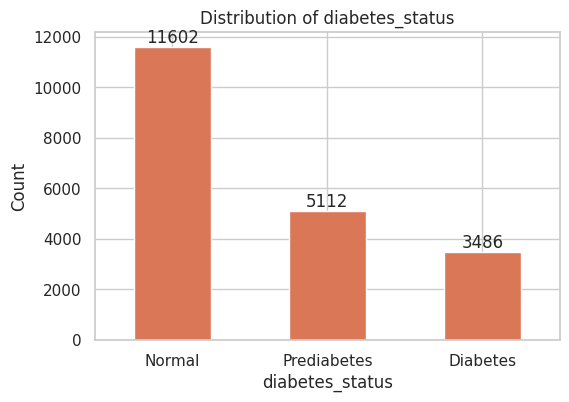

In [ ]:
# 1. Bar chart - target class distribution
ax = df_dash['diabetes_status'].value_counts().reindex(order).plot(kind='bar', color=COLOR, figsize=(6, 4))
ax.bar_label(ax.containers[0])
ax.set_title('Distribution of diabetes_status'); ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=0)
plt.show()

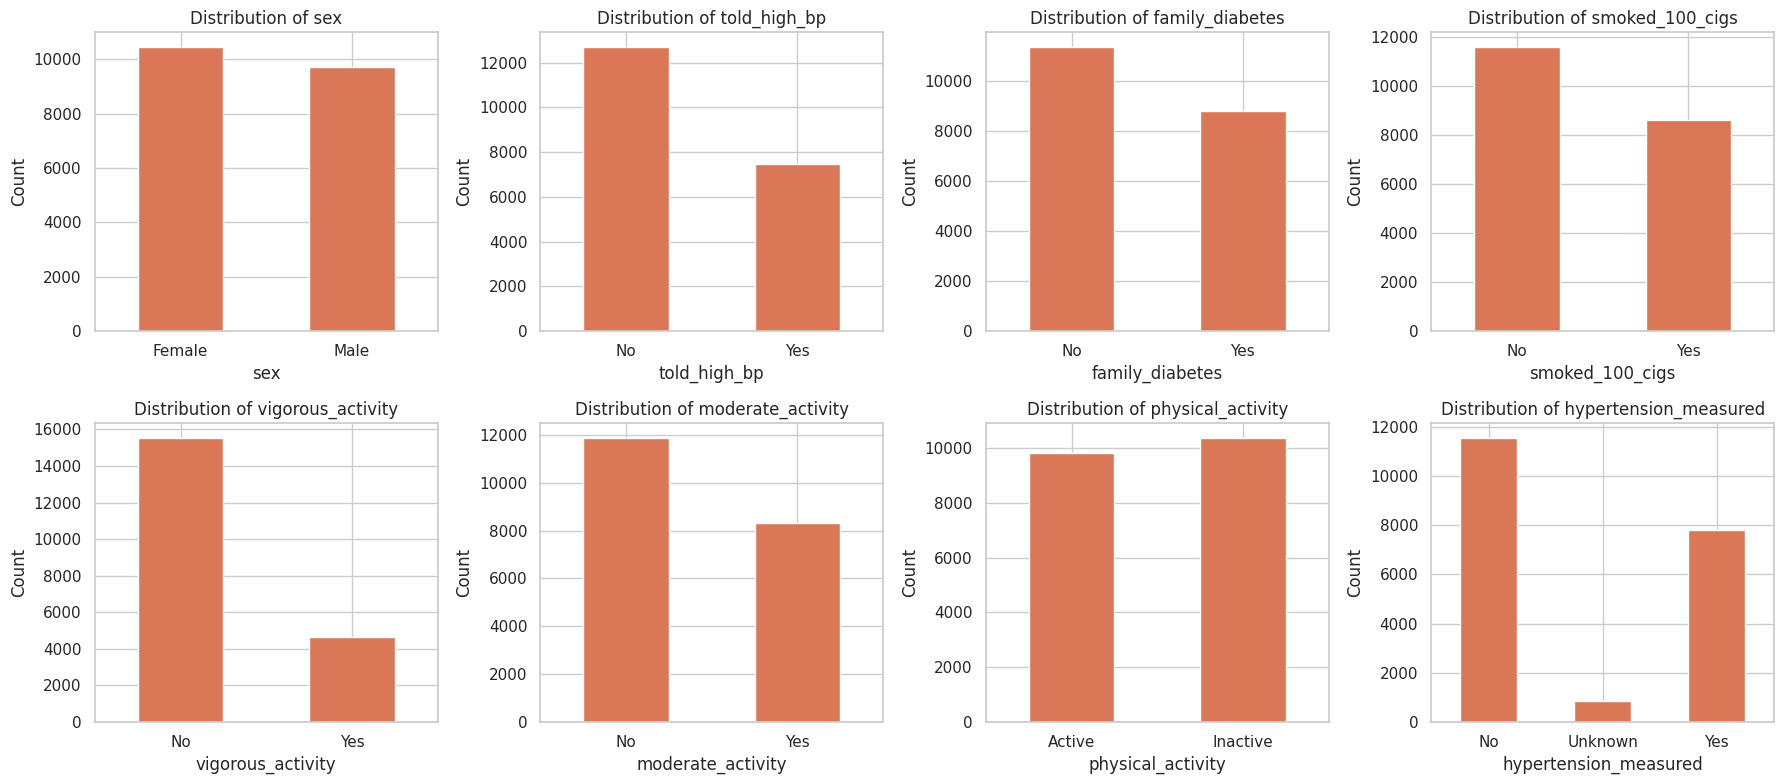

In [ ]:
# 2. Bar chart grid - distribution of each binary feature
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), binary_cols):
    df_dash[col].value_counts().sort_index().plot(kind='bar', ax=ax, color=COLOR)
    ax.set_title(f'Distribution of {col}'); ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

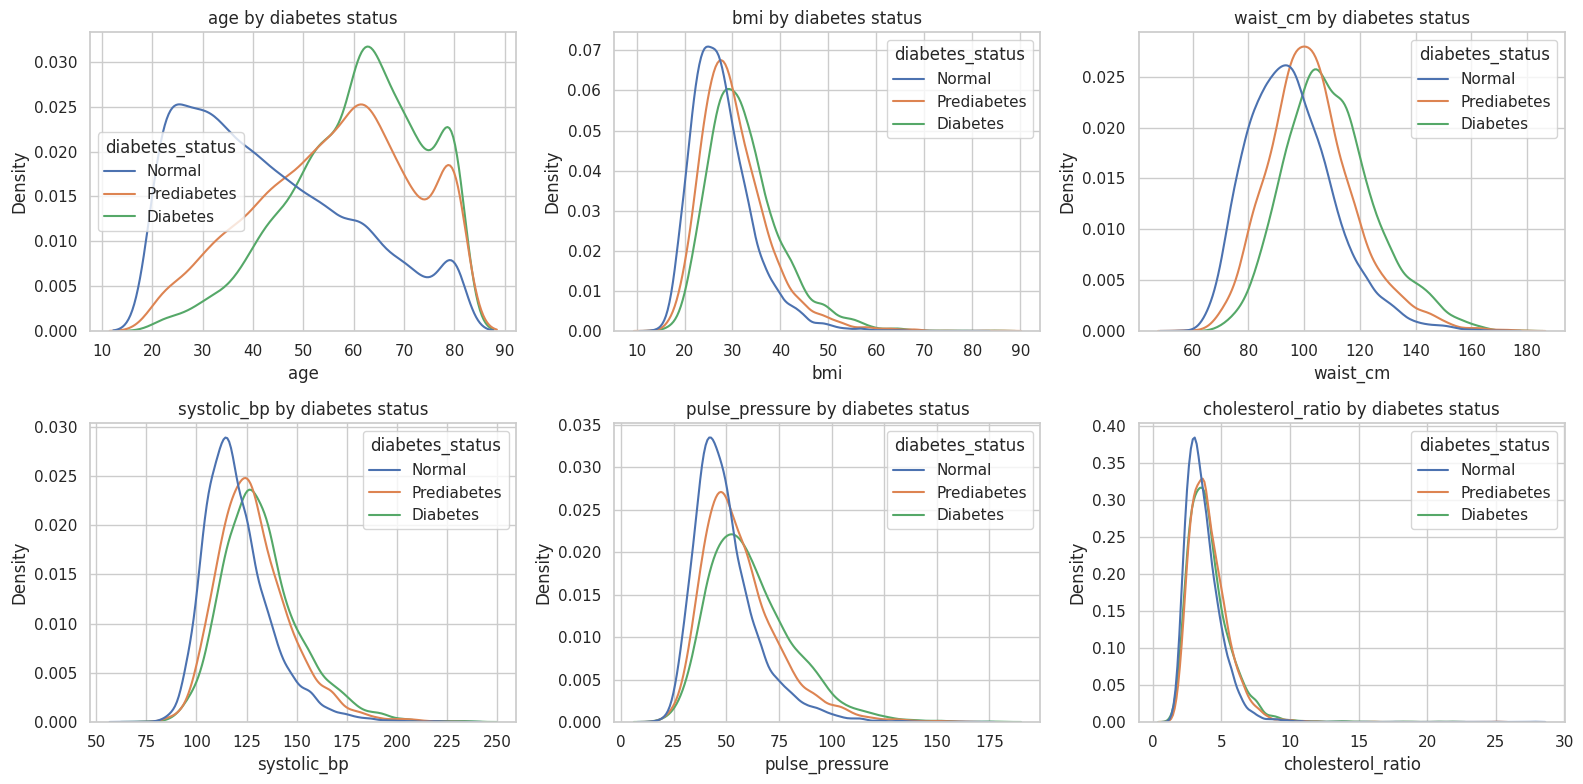

In [ ]:
# 3. Density plots - overlapping distributions by diabetes group
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), ['age', 'bmi', 'waist_cm', 'systolic_bp', 'pulse_pressure', 'cholesterol_ratio']):
    sns.kdeplot(data=df_dash, x=col, hue='diabetes_status', hue_order=order, common_norm=False, ax=ax)
    ax.set_title(f'{col} by diabetes status')
plt.tight_layout(); plt.show()

In [ ]:
for c in binary_cols:
    print(c, df_dash[c].unique())

sex ['Male' 'Female']
told_high_bp ['No' 'Yes']
family_diabetes ['Yes' 'No']
smoked_100_cigs ['No' 'Yes']
vigorous_activity ['No' 'Yes']
moderate_activity ['No' 'Yes']
physical_activity ['Inactive' 'Active']
hypertension_measured ['No' 'Yes' 'Unknown']


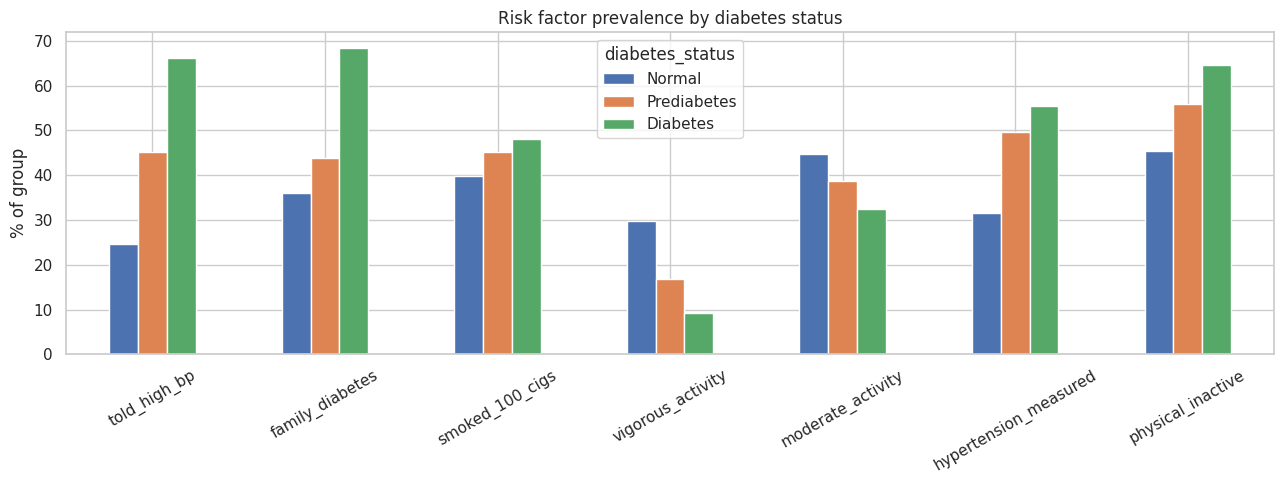

In [ ]:
# 4. Grouped bar chart - % of each diabetes group with each risk factor
yes_cols = ['told_high_bp', 'family_diabetes', 'smoked_100_cigs',
            'vigorous_activity', 'moderate_activity', 'hypertension_measured']
risk = pd.DataFrame({c: df_dash[c].map({'Yes': 1, 'No': 0}) for c in yes_cols})
risk['physical_inactive'] = df_dash['physical_activity'].map({'Active': 0, 'Inactive': 1})
prev = risk.groupby(df_dash['diabetes_status']).mean().loc[order] * 100
ax = prev.T.plot(kind='bar', figsize=(13, 5))
ax.set_title('Risk factor prevalence by diabetes status'); ax.set_ylabel('% of group')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

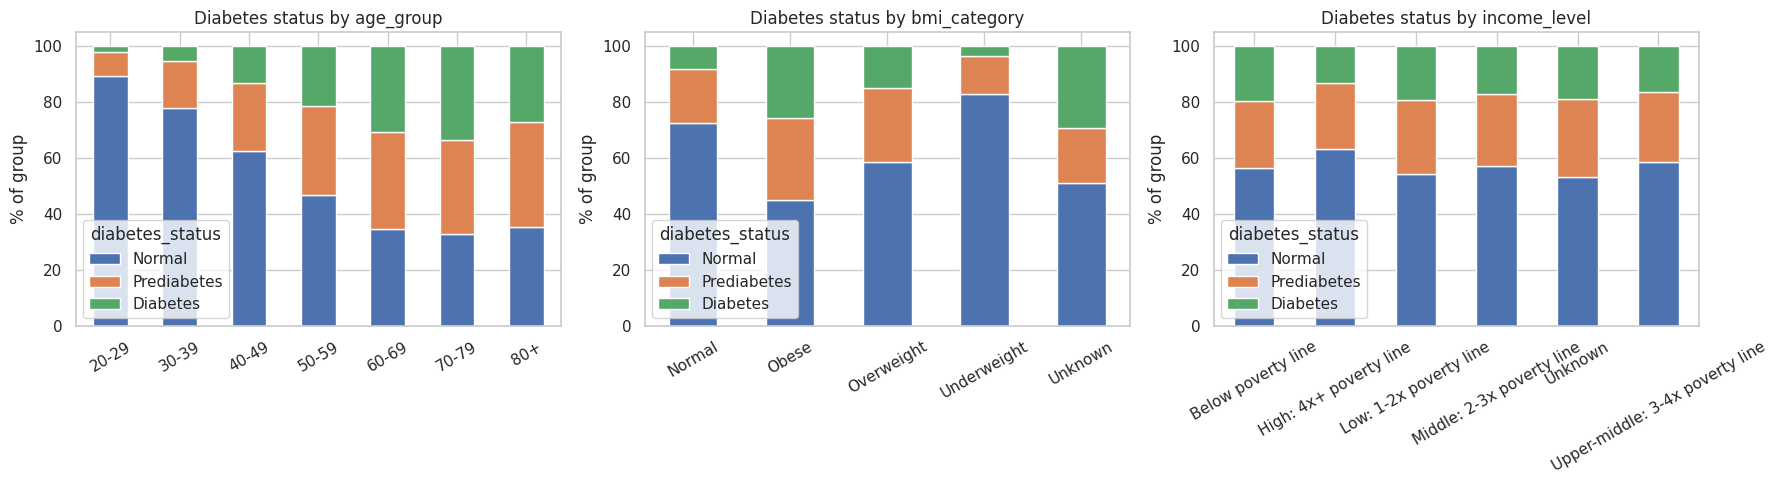

In [ ]:
# 5. Stacked bar charts - diabetes status mix by age, BMI, and income group
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, g in zip(axes, ['age_group', 'bmi_category', 'income_level']):
    pd.crosstab(df_dash[g], df_dash['diabetes_status'], normalize='index')[order].mul(100).plot(kind='bar', stacked=True, ax=ax)
    ax.set_title(f'Diabetes status by {g}'); ax.set_xlabel(''); ax.set_ylabel('% of group')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

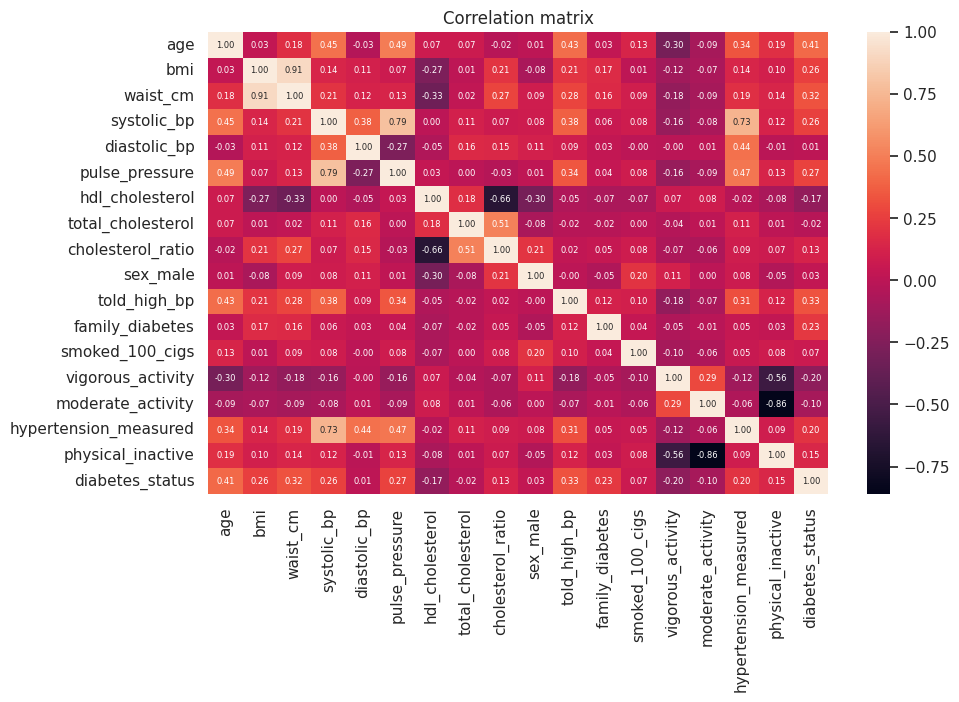

In [ ]:
# 6. Heatmap - correlations between features and the target (everything converted to numbers in a temp copy)
tmp = df_dash[numeric_cols].copy()
tmp['sex_male'] = df_dash['sex'].map({'Female': 0, 'Male': 1})
for c in yes_cols:
    tmp[c] = df_dash[c].map({'Yes': 1, 'No': 0})
tmp['physical_inactive'] = df_dash['physical_activity'].map({'Active': 0, 'Inactive': 1})
tmp['diabetes_status'] = df_dash['diabetes_status'].map({'Normal': 0, 'Prediabetes': 1, 'Diabetes': 2})
plt.figure(figsize=(10, 6))
sns.heatmap(tmp.corr(), annot=True, fmt='.2f', annot_kws={'size': 6})
plt.title('Correlation matrix')
plt.show()

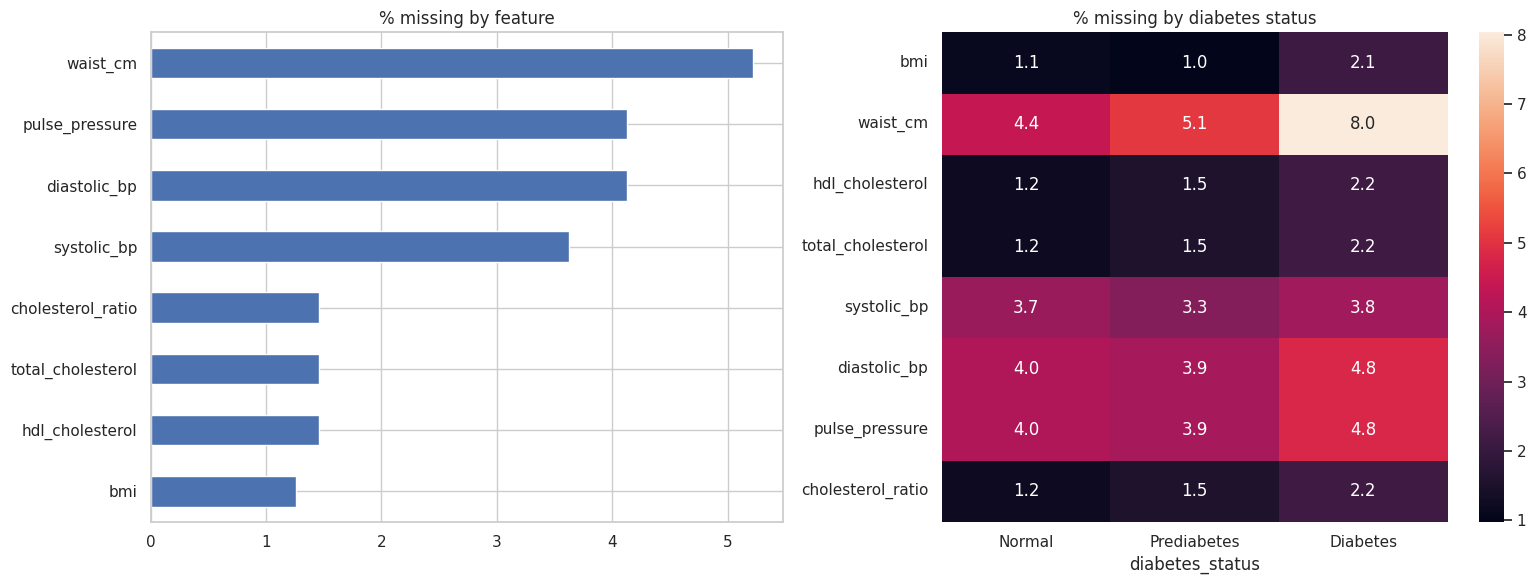

In [ ]:
# 7. Bar chart + heatmap - % missing per feature, and by diabetes group
miss = df_dash.isna().mean().mul(100)
miss = miss[miss > 0].sort_values()
by_group = df_dash.drop(columns='diabetes_status').isna().groupby(df_dash['diabetes_status']).mean().loc[order].mul(100)
by_group = by_group.loc[:, by_group.sum() > 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
miss.plot(kind='barh', ax=axes[0])
axes[0].set_title('% missing by feature')
sns.heatmap(by_group.T, annot=True, fmt='.1f', ax=axes[1])
axes[1].set_title('% missing by diabetes status')
plt.tight_layout(); plt.show()

In [ ]:
# Scraped age-adjusted diabetes prevalence (adults 20-79, % by country) from the IDF Diabetes Atlas, cleaned it, removed regional aggregates, and saved it as a CSV to compare 2024 against projected 2050.

url = "https://diabetesatlas.org/data-by-indicator/diabetes-estimates-20-79-y/age-adjusted-comparative-prevalence-of-diabetes/"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36"}
response = requests.get(url, headers=headers, timeout=30)
print("Status:", response.status_code)

tables = pd.read_html(StringIO(response.text))
print("Tables found:", len(tables), [t.shape for t in tables])
data = max(tables, key=lambda t: t.shape[1])
print(data.head())

data = data.iloc[:, :5].copy()
data.columns = ['Country', '2000', '2011', '2024', '2050']
for c in ['2000', '2011', '2024', '2050']:
    data[c] = pd.to_numeric(data[c], errors='coerce')

data.to_csv("idf_diabetes_prevalence.csv", index=False)

regions = ['Africa', 'Europe', 'Middle East and North Africa', 'North America and Caribbean',
           'South and Central America', 'South-East Asia', 'Western Pacific', 'Global']
countries = data[~data['Country'].isin(regions)].copy()
print(countries.shape)

Status: 200
Tables found: 2 [(223, 5), (223, 2)]
           Country or Territory Country or Territory.1 Country or Territory.2  \
0                        Africa                    1.2                    4.5   
1                        Europe                    4.9                    6.7   
2  Middle East and North Africa                    7.7                   11.0   
3   North America and Caribbean                    7.8                   10.7   
4     South and Central America                    3.7                    9.2   

   Country or Territory.3  Country or Territory.4  
0                     5.0                     5.9  
1                     8.0                     9.4  
2                    19.9                    22.8  
3                    13.8                    15.3  
4                    10.1                    11.5  
(215, 5)


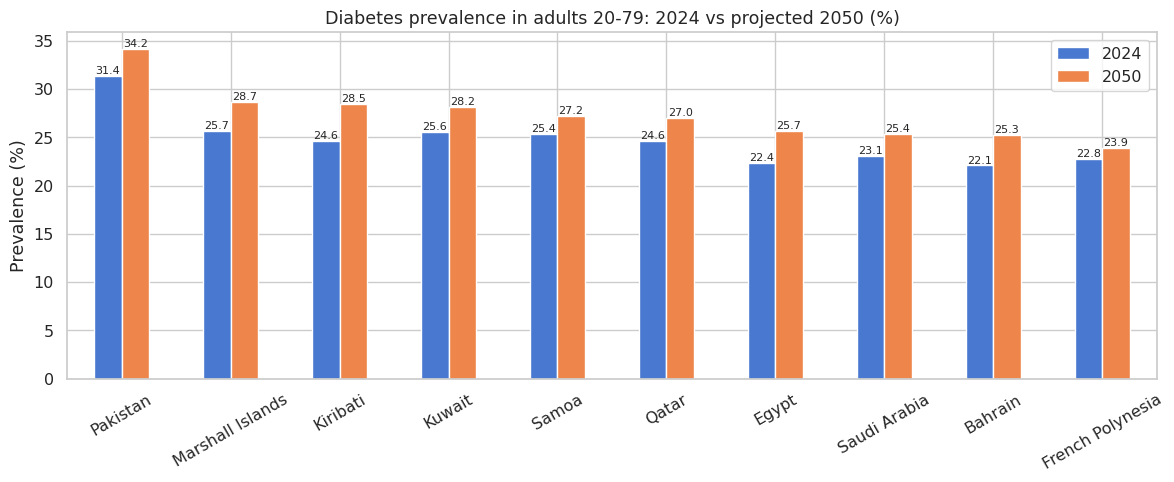

In [ ]:
# 8. Grouped bar chart - top 10 countries by 2050 prevalence, 2024 vs 2050
top = countries.sort_values('2050', ascending=False).head(10).set_index('Country')[['2024', '2050']]
ax = top.plot(kind='bar', figsize=(12, 5))
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=8)
ax.set_title('Diabetes prevalence in adults 20-79: 2024 vs projected 2050 (%)')
ax.set_ylabel('Prevalence (%)'); ax.set_xlabel('')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

In [ ]:
# Scraped the number of adults (20-79) with diabetes per country from the IDF Diabetes Atlas (published in thousands), kept only 2024 and projected 2050, converted to millions, removed regional aggregates, and saved it as a CSV.

url = "https://diabetesatlas.org/data-by-indicator/diabetes-estimates-20-79-y/people-with-diabetes-in-1000s/"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36"}
response = requests.get(url, headers=headers, timeout=30)
print("Status:", response.status_code)

tables = pd.read_html(StringIO(response.text))
counts = max(tables, key=lambda t: t.shape[1]).iloc[:, :5].copy()
counts.columns = ['Country', '2000', '2011', '2024', '2050']
counts = counts[['Country', '2024', '2050']].copy()
for c in ['2024', '2050']:
    counts[c] = pd.to_numeric(counts[c].astype(str).str.replace(',', ''), errors='coerce') / 1000

regions = ['Africa', 'Europe', 'Middle East and North Africa', 'North America and Caribbean',
           'South and Central America', 'South-East Asia', 'Western Pacific', 'Global']
counts = counts[~counts['Country'].isin(regions)].reset_index(drop=True)
counts.to_csv("idf_diabetes_counts_millions.csv", index=False)

print(counts.shape)
print(counts.sort_values('2024', ascending=False).head(10))

Status: 200
(215, 3)
                      Country      2024      2050
38                      China  147.9812  168.2892
88                      India   89.8269  156.7407
205  United States of America   38.5364   43.0253
146                  Pakistan   34.5324   70.1893
89                  Indonesia   20.4264   28.5840
25                     Brazil   16.6214   24.0257
14                 Bangladesh   13.8774   23.0710
125                    Mexico   13.5874   19.9469
58                      Egypt   13.2145   24.7326
97                      Japan   10.7635    9.4462


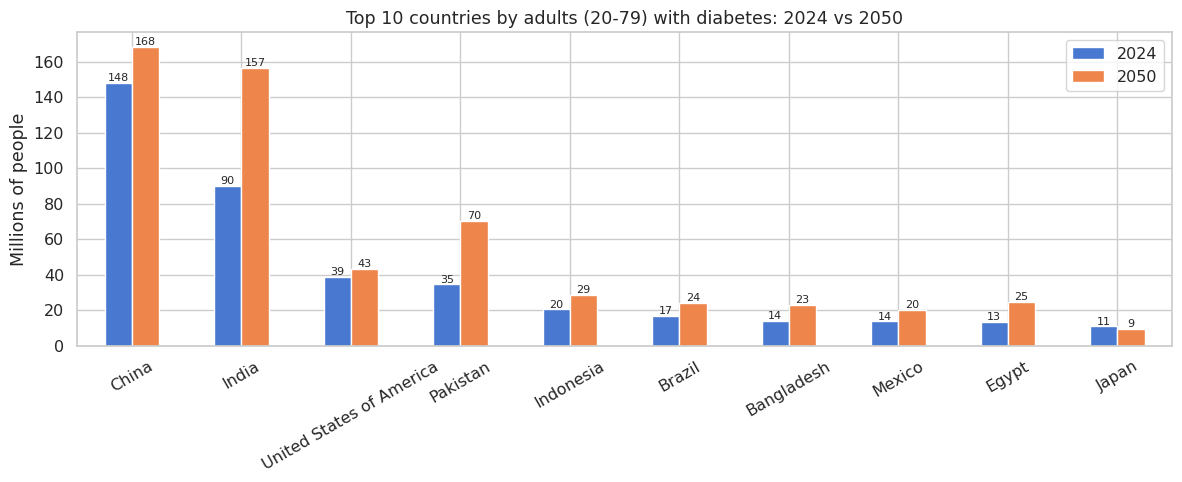

In [ ]:
# 9. Grouped bar chart - top 10 countries by number of adults (20-79) with diabetes, 2024 vs projected 2050 (millions)
top = counts.sort_values('2024', ascending=False).head(10).set_index('Country')[['2024', '2050']]
ax = top.plot(kind='bar', figsize=(12, 5))
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f', fontsize=8)
ax.set_title('Top 10 countries by adults (20-79) with diabetes: 2024 vs 2050')
ax.set_ylabel('Millions of people'); ax.set_xlabel('')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

In [ ]:
# Saving Extract data into csv
prevalence = countries[['Country', '2024', '2050']].rename(columns={'2024': 'prevalence_2024_pct', '2050': 'prevalence_2050_pct'})
count = counts[['Country', '2024', '2050']].rename(columns={'2024': 'patients_2024_millions', '2050': 'patients_2050_millions'})

prevalence.to_csv("idf_prevalence_2024_2050.csv", index=False)
count.to_csv("idf_patients_2024_2050.csv", index=False)

files.download("idf_prevalence_2024_2050.csv")
files.download("idf_patients_2024_2050.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Preprocessing Pipeline

### 7.1 Train-Test Split

The data is split into 80% training and 20% test sets, stratified by `diabetes_status` so that both sets keep the same class proportions. The test set is not used for any decision (imputation, tuning, or model selection) until the final evaluation.

In [49]:
df_dash.columns

Index(['SEQN', 'sex', 'age', 'education', 'cycle', 'bmi', 'waist_cm',
       'told_high_bp', 'family_diabetes', 'smoked_100_cigs',
       'vigorous_activity', 'moderate_activity', 'hdl_cholesterol',
       'total_cholesterol', 'diabetes_status', 'systolic_bp', 'diastolic_bp',
       'pulse_pressure', 'cholesterol_ratio', 'physical_activity',
       'hypertension_measured', 'income_level', 'age_group', 'bmi_category'],
      dtype='object')

In [50]:
print(df[["systolic_bp", "hypertension_measured"]].corr().iloc[0, 1])

print(df[["moderate_activity", "physical_activity"]].corr().iloc[0, 1])

print(df[["systolic_bp", "pulse_pressure"]].corr().iloc[0, 1])

print(df[["total_cholesterol", "cholesterol_ratio"]].corr().iloc[0, 1])


0.7313535021530326
0.8604558752892967
0.7689627090745286
0.5091138615142227


### Removing redundant features for modeling

I checked the correlation between each engineered feature and the column it was built from:

| Feature pair | Correlation | Decision |
|---|---|---|
| systolic_bp vs hypertension_measured | 0.73 | Remove `hypertension_measured` |
| moderate_activity vs physical_activity | 0.86 | Remove `physical_activity` |
| systolic_bp vs pulse_pressure | 0.77 | Remove `pulse_pressure` |
| total_cholesterol vs cholesterol_ratio | 0.51 | Keep `cholesterol_ratio` |

**Reasoning:**
- `hypertension_measured` is a fixed threshold on systolic and diastolic BP (≥130 or ≥80), so it carries no new information beyond those two columns.
- `physical_activity` is only a combination ("vigorous or moderate") of two columns already in the data. Keeping the originals preserves more detail.
- `pulse_pressure` is exactly systolic minus diastolic. Both are already included, so it is redundant. For linear models (Logistic Regression, SVC, MLP) it would also cause perfect multicollinearity.
- `cholesterol_ratio` has only moderate correlation with `total_cholesterol` (0.51) and combines it with HDL into a standard heart-risk measure, which tree models cannot easily build themselves. It is kept.

In [51]:
df_dash['income_level'].value_counts()

,count
income_level,
Low: 1-2x poverty line,4916
High: 4x+ poverty line,4610
Below poverty line,3983
Middle: 2-3x poverty line,2757
Upper-middle: 3-4x poverty line,1998
Unknown,1936


In [52]:

numeric_cols = ["age", "bmi", "waist_cm", "hdl_cholesterol", "total_cholesterol",
                "systolic_bp", "diastolic_bp", "cholesterol_ratio"]

ordinal_cols = ["education", "income_level"]

nominal_cols = ["sex", "told_high_bp", "family_diabetes", "smoked_100_cigs",
                "vigorous_activity", "moderate_activity"]

ordinal_orders = [
    ["Less than 9th grade", "9th-11th grade", "High school graduate", "Some college", "College graduate"],
    ["Below poverty line", "Low: 1-2x poverty line", "Middle: 2-3x poverty line",
     "Upper-middle: 3-4x poverty line", "High: 4x+ poverty line"],
]

df_model = df_dash[numeric_cols + ordinal_cols +  nominal_cols+ ['diabetes_status']].copy()

X = df_model.drop(columns="diabetes_status")
y = df_model["diabetes_status"].map({"Normal": 0, "Prediabetes": 1, "Diabetes": 2})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3)*100)
print(y_test.value_counts(normalize=True).round(3)*100)

(16160, 16) (4040, 16)
diabetes_status
0    57.4
1    25.3
2    17.3
Name: proportion, dtype: float64
diabetes_status
0    57.5
1    25.3
2    17.3
Name: proportion, dtype: float64


### 7.2 Model Pipelines with Preprocessing

Each model is wrapped in a Scikit-learn `Pipeline` with two steps: the shared `ColumnTransformer` preprocessor, then the classifier. The preprocessor handles each feature type separately:

- **Numeric features:** missing values are filled with the training-set median, then scaled with `RobustScaler`, which is less affected by outliers than standard scaling. Fewer than 6% of values are missing in any numeric column.
- **Ordinal features** (`education`, `income_level`): encoded in their natural order. Respondents with unreported income are given the most common level.
- **Nominal features** (Yes/No flags, sex, activity): all are binary, so each is encoded as a single 0/1 column. This avoids the extra columns one-hot encoding would create.

Because the preprocessor is the first step of every pipeline, the imputers, encoders and scaler are fitted only on the training portion of each cross-validation fold and then applied to the validation fold. This prevents data leakage. `SEQN`, `cycle`, `age_group`, and `bmi_category` are not used as features.

Six models are compared using the same preprocessed features and the same folds: Extra Trees, HistGradientBoosting, XGBoost, CatBoost, LightGBM, and Support Vector Machine (SVM). The models use different learning approaches, with hyperparameters configured to control complexity and reduce overfitting.

In [53]:
df_model[numeric_cols].head()

,age,bmi,waist_cm,hdl_cholesterol,total_cholesterol,systolic_bp,diastolic_bp,cholesterol_ratio
0,22.0,23.3,81.0,41.0,168.0,110.666667,75.0,4.097561
1,44.0,23.2,80.1,28.0,190.0,118.000000,60.0,6.785714
2,21.0,20.1,69.6,43.0,132.0,124.666667,78.0,3.069767
3,43.0,33.3,120.4,73.0,169.0,102.000000,71.0,2.315068
5,34.0,23.3,89.4,55.0,171.0,106.000000,69.0,3.109091


In [54]:
cat_cols = ["sex", "education", "income_level", "told_high_bp", "family_diabetes", "smoked_100_cigs", "vigorous_activity", "moderate_activity"]
df_model[cat_cols].head()

,sex,education,income_level,told_high_bp,family_diabetes,smoked_100_cigs,vigorous_activity,moderate_activity
0,Male,High school graduate,Upper-middle: 3-4x poverty line,No,Yes,No,No,No
1,Female,Some college,Low: 1-2x poverty line,No,No,No,Yes,Yes
2,Male,High school graduate,Below poverty line,No,No,No,No,No
3,Female,High school graduate,Middle: 2-3x poverty line,No,Yes,Yes,No,No
5,Female,College graduate,High: 4x+ poverty line,No,Yes,No,Yes,Yes


In [55]:
df_model.isna().sum()

,0
age,0
bmi,254
waist_cm,1054
hdl_cholesterol,294
total_cholesterol,294
systolic_bp,733
diastolic_bp,733
cholesterol_ratio,294
education,0
income_level,0


In [56]:
preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
    ]), numeric_cols),
    ("ord", Pipeline([
        ("encoder", OrdinalEncoder(categories=ordinal_orders,
                                   handle_unknown="use_encoded_value", unknown_value=np.nan)),
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ]), ordinal_cols),
    ("bin", OrdinalEncoder(dtype=int, handle_unknown="use_encoded_value", unknown_value=-1), nominal_cols),
], remainder="drop")

X_train_t = preprocessor.fit_transform(X_train)
print(X_train_t.shape)
print(np.isnan(X_train_t).sum())   # should be 0

(16160, 16)
0


In [94]:

pipeline_et = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=500,
        max_depth=12,
        min_samples_leaf=20,
        max_features="sqrt",
        n_jobs=-1,
        random_state=42
    ))
])


pipeline_hgb = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=500,
        max_depth=5,
        max_leaf_nodes=15,
        min_samples_leaf=50,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42
    ))
])

pipeline_xgb = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        n_estimators=400,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.7,
        reg_lambda=5.0,
        gamma=0.5,
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    ))
])

pipeline_catboost = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CatBoostClassifier(
        iterations=500,
        learning_rate=0.04,
        depth=5,
        l2_leaf_reg=10,
        loss_function="MultiClass",
        bootstrap_type="Bernoulli",
        subsample=0.8,
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    ))
])

pipeline_lgbm = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LGBMClassifier(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=15,
        max_depth=5,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.7,
        reg_lambda=5.0,
        n_jobs=-1,
        random_state=42,
        verbose=-1
    ))
])

pipeline_svm = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        cache_size=500,
        random_state=42
    ))
])


## 8. Model Training & Cross-Validation

Six candidate pipelines (ExtraTrees, HistGradientBoosting, XGBoost, CatBoost, LightGBM, and an RBF-kernel SVM) are benchmarked with stratified 5-fold cross-validation on the training set. Each pipeline applies the same preprocessing, followed by the classifier. Stratification keeps the class proportions the same in every fold. The test set is not used here.

These baseline models use no class weights, and their results serve as the "no handling" reference for the class-imbalance comparison in Section 9. Each model is scored with accuracy, macro precision, macro recall (equal to balanced accuracy), macro F1, and one-vs-rest ROC-AUC. Because the classes are imbalanced, accuracy alone is misleading, so models are ranked by ROC-AUC and macro F1.

In [97]:
models = {
    "ExtraTree": pipeline_et,
    "HistGradientBoosting": pipeline_hgb,
    "XGBoost": pipeline_xgb,
    "CatBoost": pipeline_catboost,
    "LightGBM": pipeline_lgbm,
    "SVM": pipeline_svm
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc_ovr"]

cv_results1 = {}

for name, pipeline in models.items():
    print(f"Running cross-validation: {name}...")
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=jobs, error_score="raise")
    cv_results1[name] = {metric: scores[f"test_{metric}"].mean() for metric in scoring}

Running cross-validation: ExtraTree...
Running cross-validation: HistGradientBoosting...
Running cross-validation: XGBoost...
Running cross-validation: CatBoost...
Running cross-validation: LightGBM...
Running cross-validation: SVM...


In [98]:
results_df = pd.DataFrame(cv_results1).T.sort_values("f1_macro", ascending=False)
results_df.round(4)

,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr
LightGBM,0.6349,0.5460,0.5271,0.5266,0.7774
HistGradientBoosting,0.6354,0.5448,0.5257,0.5237,0.7768
CatBoost,0.6374,0.5468,0.5245,0.5234,0.7807
XGBoost,0.6368,0.5456,0.5228,0.5214,0.7805
SVM,0.6337,0.5454,0.4950,0.4884,0.7584
ExtraTree,0.6216,0.4995,0.4698,0.4386,0.7690


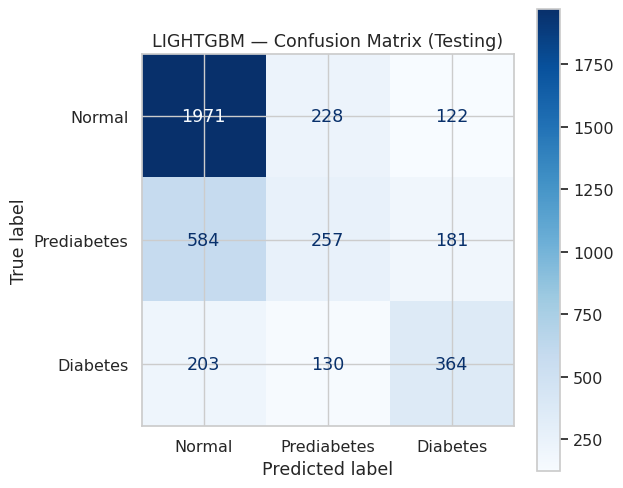

In [125]:
pipeline_lgbm.fit(X_train, y_train)
y_pred_lgbm = pipeline_lgbm.predict(X_test)

cm = confusion_matrix(y_test, y_pred_lgbm, labels=pipeline_lgbm.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prediabetes", "Diabetes"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("LIGHTGBM — Confusion Matrix (Testing)")
plt.show()

## 9. Class Imbalance Handling

The target is imbalanced: about 57% Normal, 25% Prediabetes, and 17% Diabetes. Three strategies are compared using the same stratified 5-fold cross-validation:

- **No handling:** the same models without any weights (baseline). These results were already obtained in Step 8, so they are reused here.
- **Class weighting:** balanced class weights in the models that support them. XGBoost has no class-weight option, so it receives the equivalent balanced per-sample weights.
- **SMOTE:** synthetic minority-class samples generated inside an `imblearn` pipeline, so oversampling is applied only to the training part of each fold and never to validation data

Strategies are compared on ROC-AUC, macro F1, and balanced accuracy, since plain accuracy rewards ignoring the minority classes.

In [101]:

pipeline_lgbm_smote = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LGBMClassifier(
        n_estimators=500, learning_rate=0.03, num_leaves=15, max_depth=5,
        min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
        reg_lambda=5.0, n_jobs=-1, random_state=42, verbose=-1
    )),
])

pipeline_lgbm_smote.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['age', 'bmi', 'waist_cm',
                                                   'hdl_cholesterol',
                                                   'total_cholesterol',
                                                   'systolic_bp',
                                                   'diastolic_bp',
                                                   'cholesterol_ratio']),
                                                 ('ord',
                                                  Pipeline(steps=[('encoder',
                                                                   OrdinalEncoder(categories=[['Less '
                                                                                               'than '
                                                                                               '9t...
                                                  ['sex', 'told_high_bp',
                                                   'family_diabetes',
                                                   'smoked_100_cigs',
                                                   'vigorous_activity',
                                                   'moderate_activity'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
                 LGBMClassifier(colsample_bytree=0.7, learning_rate=0.03,
                                max_depth=5, min_child_samples=50,
                                n_estimators=500, n_jobs=-1, num_leaves=15,
                                random_state=42, reg_lambda=5.0, subsample=0.8,
                                subsample_freq=1, verbose=-1))])

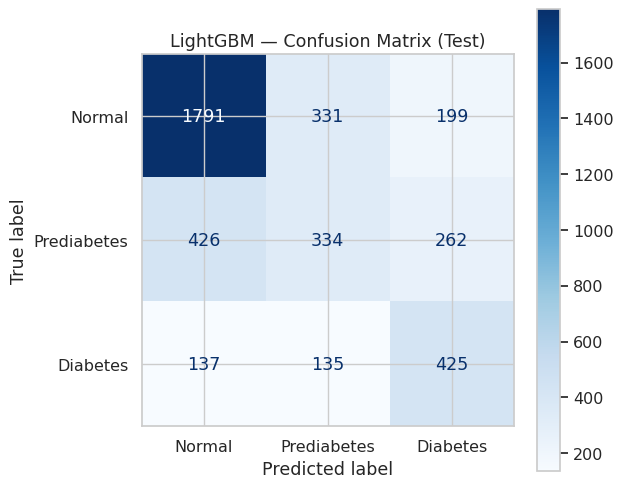

In [102]:
y_pred_smote = pipeline_lgbm_smote.predict(X_test)

cm = confusion_matrix(y_test, y_pred_smote, labels=pipeline_lgbm_smote.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prediabetes", "Diabetes"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("LightGBM — Confusion Matrix (Test)")
plt.show()

### SMOTE Oversampling Result

SMOTE was applied inside the pipeline, after preprocessing and only on the training data, so the test set kept its original class distribution. The oversampling balanced the training classes but did not improve performance on the test set.

- Overall results stayed in the same range as the models without oversampling (accuracy 0.63, macro F1 0.56).
- **Prediabetes is still the weakest class.** Only 334 of 1,022 true Prediabetes cases were found (recall 0.33, F1 0.37). Of the rest, 426 were predicted as Normal and 262 as Diabetes.
- Precision for Prediabetes is also low (0.42), so many cases predicted as Prediabetes are really Normal or Diabetes.
- The model separates Normal and Diabetes much better than it finds Prediabetes. This is expected, because Prediabetes lies between the two classes on every available feature, and SMOTE only creates synthetic points between existing neighbours, so it adds no new information about what separates them.

Conclusion: SMOTE did not help with this data. The limit comes from the features (no glucose or HbA1c), not from class imbalance, so class weighting and threshold tuning are used instead.

### Stacking Ensemble (class-weighted)

The best-performing pipelines are combined into a stacking classifier. Six base models with different learning mechanisms are used: ExtraTrees (bagged trees), HistGradientBoosting, XGBoost, CatBoost and LightGBM (four gradient-boosting implementations), and Logistic Regression (a linear model). Because they learn in different ways, their errors differ, and combining them can capture patterns that a single model misses.

- **Meta-learner:** each base model produces class probabilities, and a Logistic Regression learns how much to trust each model for each class.
- **Leakage control:** the base-model probabilities given to the meta-learner are produced out-of-fold (3-fold stratified cross-validation inside each training set), so the meta-learner never sees predictions made on data a base model was trained on.
- **Class imbalance:** balanced class weights are applied at every level (all base models and the meta-learner), so Prediabetes and Diabetes carry the same total importance as Normal. XGBoost, which has no class-weight option, receives equivalent balanced per-sample weights.
- **Preprocessing:** the same `ColumnTransformer` is used as the first step of the pipeline, so imputation, encoding and scaling are fitted only on the training data.

The stack is evaluated with the same stratified 5-fold cross-validation as the individual models, so its scores are directly comparable. If it does not clearly outperform the best single model, this indicates that the limit comes from the available features rather than the choice of model.

In [100]:

# XGBoost do no have class_weight option, so this subclass compute balanced
# per-sample weights inside fit(). The result is identical to class_weight="balanced".
class XGBBalanced(XGBClassifier):
    def fit(self, X, y, **kwargs):
        return super().fit(X, y, sample_weight=compute_sample_weight("balanced", y), **kwargs)

pipeline_et_w = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=500,
        max_depth=12,
        min_samples_leaf=20,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ))
])

pipeline_hgb_w = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=500, max_depth=5, max_leaf_nodes=15,
        min_samples_leaf=50, l2_regularization=1.0, class_weight="balanced",
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=42
    ))
])

pipeline_xgb_w = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBBalanced(
        objective="multi:softprob", eval_metric="mlogloss", n_estimators=400,
        learning_rate=0.03, max_depth=3, min_child_weight=10, subsample=0.8,
        colsample_bytree=0.7, reg_lambda=5.0, gamma=0.5, tree_method="hist",
        n_jobs=-1, random_state=42
    ))
])


pipeline_catboost_w = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CatBoostClassifier(
        iterations=500, learning_rate=0.04, depth=5, l2_leaf_reg=10,
        loss_function="MultiClass", auto_class_weights="Balanced",
        bootstrap_type="Bernoulli", subsample=0.8, random_seed=42,
        verbose=False, allow_writing_files=False
    ))
])

pipeline_lgbm_w = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LGBMClassifier(
        n_estimators=500, learning_rate=0.03, num_leaves=15, max_depth=5,
        min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
        reg_lambda=5.0, class_weight="balanced", n_jobs=-1, random_state=42, verbose=-1
    ))
])

pipeline_svm_w = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        cache_size=500,
        random_state=42
    ))
])

In [103]:
models_w = {
    "ExtraTree": pipeline_et_w,
    "HistGradientBoosting": pipeline_hgb_w,
    "XGBoost": pipeline_xgb_w,
    "CatBoost": pipeline_catboost_w,
    "LightGBM": pipeline_lgbm_w,
    "SVM": pipeline_svm_w
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc_ovr"]

cv_results2 = {}

for name, pipeline in models_w.items():
    print(f"Running cross-validation (class weighted): {name}...")
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=-1, error_score="raise")
    cv_results2[name] = {metric: scores[f"test_{metric}"].mean() for metric in scoring}

pd.DataFrame(cv_results2).T.round(4).sort_values("f1_macro", ascending=False)

Running cross-validation (class weighted): ExtraTree...
Running cross-validation (class weighted): HistGradientBoosting...
Running cross-validation (class weighted): XGBoost...
Running cross-validation (class weighted): CatBoost...
Running cross-validation (class weighted): LightGBM...
Running cross-validation (class weighted): SVM...


,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr
XGBoost,0.5941,0.5515,0.5866,0.5551,0.7737
CatBoost,0.5923,0.5521,0.5861,0.5549,0.7740
LightGBM,0.5956,0.5498,0.5812,0.5541,0.7709
SVM,0.5861,0.5506,0.5839,0.5509,0.7765
HistGradientBoosting,0.5910,0.5474,0.5808,0.5503,0.7701
ExtraTree,0.5822,0.5329,0.5726,0.5351,0.7617


Class weighting improved macro F1 for every model. The gradient-boosting methods gained about 3 percentage points (for example, XGBoost rose from 52% to 55%), while SVM and ExtraTrees gained 6 and 10 points, because without weights they rarely predicted the minority classes. Macro recall rose by roughly 5 to 10 points, so more Prediabetes and Diabetes cases were found, while accuracy fell by about 4 points (from roughly 63% to 59%). ROC-AUC barely changed and stayed near 0.77, so weighting moves the decision threshold toward the minority classes without adding new predictive information. XGBoost, CatBoost and LightGBM performed equivalently, each with a macro F1 of about 55%.

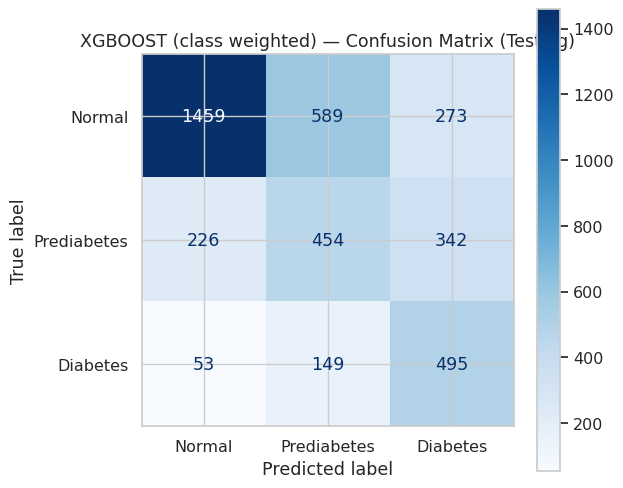

In [124]:
pipeline_xgb_w.fit(X_train, y_train)
y_pred_xg = pipeline_xgb_w.predict(X_test)

cm = confusion_matrix(y_test, y_pred_xg, labels=pipeline_xgb_w.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prediabetes", "Diabetes"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("XGBOOST (class weighted) — Confusion Matrix (Testing)")
plt.show()

In [121]:
et_s = ExtraTreesClassifier(
    n_estimators=500, max_depth=12, min_samples_leaf=20, max_features="sqrt",
    class_weight="balanced", n_jobs=-1, random_state=42
)

hgb_s = HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=500, max_depth=5, max_leaf_nodes=15,
    min_samples_leaf=50, l2_regularization=1.0, class_weight="balanced",
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=42
)

xgb_s = XGBBalanced(
    objective="multi:softprob", eval_metric="mlogloss", n_estimators=400,
    learning_rate=0.03, max_depth=3, min_child_weight=10, subsample=0.8,
    colsample_bytree=0.7, reg_lambda=5.0, gamma=0.5, tree_method="hist",
    n_jobs=-1, random_state=42
)

cat_s = CatBoostClassifier(
    iterations=500, learning_rate=0.04, depth=5, l2_leaf_reg=10,
    loss_function="MultiClass", auto_class_weights="Balanced",
    bootstrap_type="Bernoulli", subsample=0.8, random_seed=42,
    verbose=False, allow_writing_files=False
)

lgbm_s = LGBMClassifier(
    n_estimators=500, learning_rate=0.03, num_leaves=15, max_depth=5,
    min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
    reg_lambda=5.0, class_weight="balanced", n_jobs=-1, random_state=42, verbose=-1
)

logreg_s = LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5)

stack = StackingClassifier(
    estimators=[("et", et_s), ("hgb", hgb_s), ("xgb", xgb_s),
                ("cat", cat_s), ("lgbm", lgbm_s), ("lr", logreg_s)],
    final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5),
    stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=1
)

pipeline_stack_w = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", stack),

])

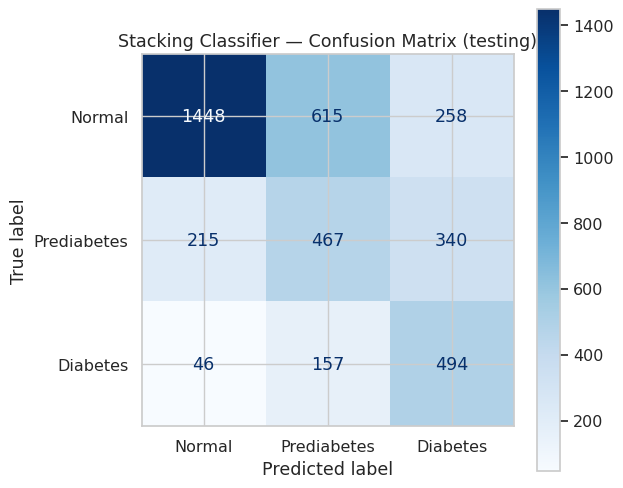

In [123]:
pipeline_stack_w.fit(X_train, y_train)
y_pred_stack = pipeline_stack_w.predict(X_test)

cm = confusion_matrix(y_test, y_pred_stack, labels=pipeline_stack_w.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Prediabetes", "Diabetes"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Stacking Classifier — Confusion Matrix (testing)")
plt.show()

## 10. Hyperparameter Tuning

Each model is tuned with a random search (`RandomizedSearchCV`) and stratified 5-fold cross-validation, using the training data only. A full grid would have thousands of combinations, so each search tries a small number of random ones instead. The ranges are centered on regularized settings (shallow trees, small learning rates, penalties, and minimum leaf sizes) to limit overfitting.

Candidates are scored on macro F1, which weights the three classes equally. For XGBoost, the training score of the best setting is compared with its cross-validation score to check for overfitting. The tuned models are then combined in one stacking classifier. The test set is not used in this step.

In [127]:
param_grid = {
    "classifier__n_estimators": [200, 400, 600],
    "classifier__learning_rate": [0.02, 0.03, 0.05],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__min_child_weight": [5, 10, 20],
    "classifier__subsample": [0.7, 0.8, 0.9],
    "classifier__colsample_bytree": [0.5, 0.7, 0.9],
    "classifier__reg_lambda": [1, 5, 10],
    "classifier__gamma": [0, 0.5, 1]
}

search_xgb = RandomizedSearchCV(
    pipeline_xgb_w, param_grid, n_iter=30, scoring="f1_macro",
    cv=cv, random_state=42, n_jobs=1, return_train_score=True, verbose=1
)
search_xgb.fit(X_train, y_train)

best = search_xgb.best_index_
print(search_xgb.best_params_)
print("CV macro F1:", round(search_xgb.best_score_, 3))
print("Train macro F1:", round(search_xgb.cv_results_["mean_train_score"][best], 3))


Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 5, 'classifier__n_estimators': 400, 'classifier__min_child_weight': 10, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__gamma': 0, 'classifier__colsample_bytree': 0.5}
CV macro F1: 0.559
Train macro F1: 0.603


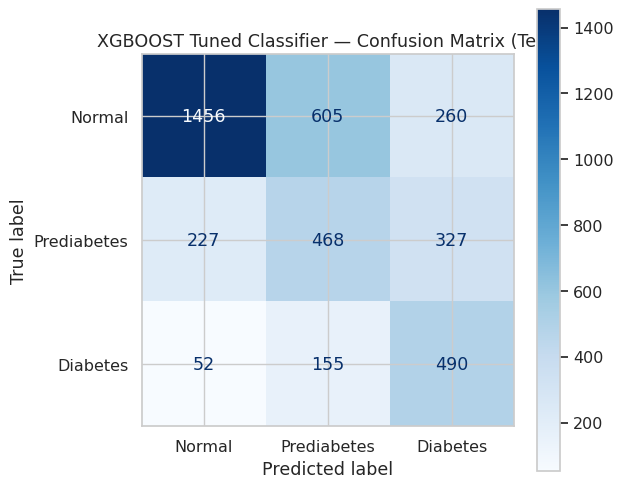

In [134]:
y_pred_tuune = search_xgb.predict(X_test)

cm = confusion_matrix(y_test, y_pred_tuune, labels=search_xgb.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("XGBOOST Tuned Classifier — Confusion Matrix (Test)")
plt.show()

In [131]:
from sklearn.base import clone


models = [
    ("et", ExtraTreesClassifier(class_weight="balanced", n_jobs=-1, random_state=42),
     {"classifier__n_estimators": [300, 500],
      "classifier__max_depth": [8, 12, 16],
      "classifier__min_samples_leaf": [10, 20, 40],
      "classifier__max_features": ["sqrt", 0.5]}, 12),

    ("hgb", HistGradientBoostingClassifier(class_weight="balanced", early_stopping=True, random_state=42),
     {"classifier__learning_rate": [0.03, 0.05, 0.1],
      "classifier__max_depth": [3, 5, 7],
      "classifier__max_leaf_nodes": [8, 15, 31],
      "classifier__min_samples_leaf": [30, 50, 100],
      "classifier__l2_regularization": [0.5, 1, 5]}, 15),

    ("cat", CatBoostClassifier(loss_function="MultiClass", auto_class_weights="Balanced",
                               allow_writing_files=False, verbose=0, random_seed=42),
     {"classifier__iterations": [300, 500],
      "classifier__learning_rate": [0.03, 0.05, 0.08],
      "classifier__depth": [4, 5, 6],
      "classifier__l2_leaf_reg": [5, 10, 20]}, 10),

    ("lgbm", LGBMClassifier(class_weight="balanced", verbose=-1, n_jobs=-1, random_state=42),
     {"classifier__n_estimators": [300, 500, 700],
      "classifier__learning_rate": [0.02, 0.03, 0.05],
      "classifier__num_leaves": [8, 15, 31],
      "classifier__min_child_samples": [30, 60, 100],
      "classifier__subsample": [0.7, 0.8, 0.9],
      "classifier__colsample_bytree": [0.5, 0.7, 0.9],
      "classifier__reg_lambda": [1, 5, 10]}, 15),

    ("lr", LogisticRegression(class_weight="balanced", max_iter=2000),
     {"classifier__C": [0.01, 0.05, 0.1, 0.5, 1, 5]}, 6),
]

tuned = [("xgb", clone(search_xgb.best_estimator_.named_steps["classifier"]))]

for name, model, grid, n in models:
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", model)])
    search = RandomizedSearchCV(pipe, grid, n_iter=n, scoring="f1_macro", cv=cv, random_state=42, n_jobs=1)
    search.fit(X_train, y_train)
    print(name, round(search.best_score_, 3), search.best_params_)
    tuned.append((name, clone(search.best_estimator_.named_steps["classifier"])))

stack = StackingClassifier(
    estimators=tuned,
    final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5),
    stack_method="predict_proba",
    cv=StratifiedKFold(3, shuffle=True, random_state=42),
    n_jobs=1
)

pipeline_final = Pipeline([("preprocessor", preprocessor), ("classifier", stack)])
pipeline_final.fit(X_train, y_train)

et 0.545 {'classifier__n_estimators': 500, 'classifier__min_samples_leaf': 10, 'classifier__max_features': 0.5, 'classifier__max_depth': 16}
hgb 0.551 {'classifier__min_samples_leaf': 100, 'classifier__max_leaf_nodes': 31, 'classifier__max_depth': 7, 'classifier__learning_rate': 0.05, 'classifier__l2_regularization': 5}
cat 0.557 {'classifier__learning_rate': 0.03, 'classifier__l2_leaf_reg': 10, 'classifier__iterations': 500, 'classifier__depth': 6}
lgbm 0.555 {'classifier__subsample': 0.7, 'classifier__reg_lambda': 5, 'classifier__num_leaves': 8, 'classifier__n_estimators': 700, 'classifier__min_child_samples': 30, 'classifier__learning_rate': 0.02, 'classifier__colsample_bytree': 0.9}
lr 0.547 {'classifier__C': 0.05}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['age', 'bmi', 'waist_cm',
                                                   'hdl_cholesterol',
                                                   'total_cholesterol',
                                                   'systolic_bp',
                                                   'diastolic_bp',
                                                   'cholesterol_ratio']),
                                                 ('ord',
                                                  Pipeline(steps=[('encoder',
                                                                   OrdinalEncoder(categories=[['Less '
                                                                                               'than '
                                                                                               '9t...
                                                                colsample_bytree=0.9,
                                                                learning_rate=0.02,
                                                                min_child_samples=30,
                                                                n_estimators=700,
                                                                n_jobs=-1,
                                                                num_leaves=8,
                                                                random_state=42,
                                                                reg_lambda=5,
                                                                subsample=0.7,
                                                                verbose=-1)),
                                                ('lr',
                                                 LogisticRegression(C=0.05,
                                                                    class_weight='balanced',
                                                                    max_iter=2000))],
                                    final_estimator=LogisticRegression(C=0.5,
                                                                       class_weight='balanced',
                                                                       max_iter=2000),
                                    n_jobs=1, stack_method='predict_proba'))])

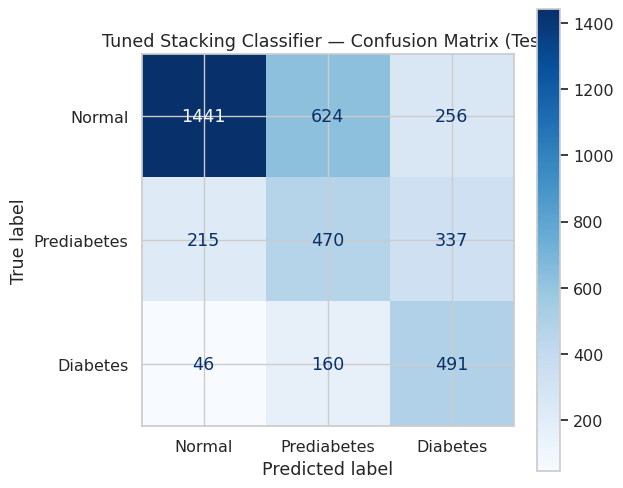

In [135]:
y_pred_stuned_stack = pipeline_final.predict(X_test)

class_names = ["Normal", "Prediabetes", "Diabetes"]
cm = confusion_matrix(y_test, y_pred_stuned_stack, labels=pipeline_final.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Tuned Stacking Classifier — Confusion Matrix (Test)")
plt.show()


## 11. Final Evaluation

The final tuned XGBoost model is evaluated on the test set, which was not used to train the model or to choose its settings. No changes are made to the model after these results.

The evaluation has a classification report (precision, recall and F1 for each class), a confusion matrix, and four overall scores: accuracy, macro precision, macro recall and macro F1. Macro scores give each of the three classes the same weight, so the smaller Prediabetes and Diabetes classes count as much as Normal.

In [136]:
final_model = search_xgb.best_estimator_
class_names = ["Normal", "Prediabetes", "Diabetes"]

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)

print(classification_report(y_test, y_pred, target_names=class_names))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 3))

              precision    recall  f1-score   support

      Normal       0.84      0.63      0.72      2321
 Prediabetes       0.38      0.46      0.42      1022
    Diabetes       0.45      0.70      0.55       697

    accuracy                           0.60      4040
   macro avg       0.56      0.60      0.56      4040
weighted avg       0.66      0.60      0.61      4040

Macro F1: 0.562


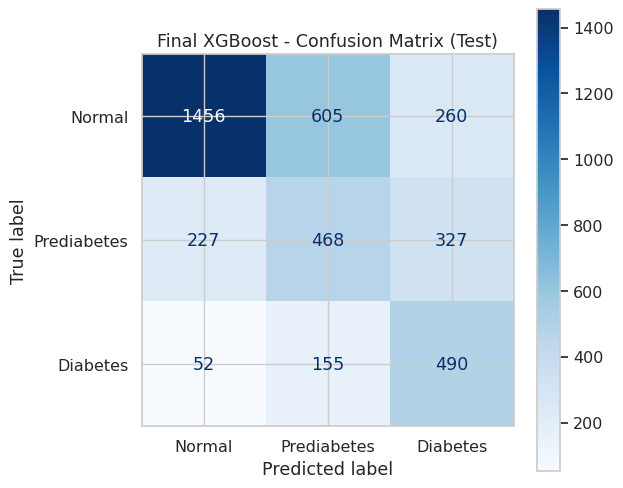

In [137]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Final XGBoost - Confusion Matrix (Test)")
plt.show()

### Threshold tuning for Prediabetes

The Prediabetes precision is low, so the Prediabetes probability is multiplied by a weight before the class is chosen. A weight below 1 makes the model predict Prediabetes less often. The weight is chosen on out-of-fold predictions from the training data only, and then applied to the test set one time.

In [147]:
oof = cross_val_predict(clone(final_model), X_train, y_train, cv=cv, method="predict_proba")

for w in np.arange(0.4, 1.11, 0.1):
    pred = (oof * [1, w, 1]).argmax(axis=1)
    p = precision_score(y_train, pred, average=None)[1]
    r = recall_score(y_train, pred, average=None)[1]
    m = f1_score(y_train, pred, average="macro")
    print(round(w, 1), "Prediabetes precision:", round(p, 3), "recall:", round(r, 3), "macro F1:", round(m, 3))

0.4 Prediabetes precision: 0.365 recall: 0.017 macro F1: 0.436
0.5 Prediabetes precision: 0.422 recall: 0.075 macro F1: 0.468
0.6 Prediabetes precision: 0.403 recall: 0.153 macro F1: 0.498
0.7 Prediabetes precision: 0.405 recall: 0.238 macro F1: 0.524
0.8 Prediabetes precision: 0.406 recall: 0.324 macro F1: 0.544
0.9 Prediabetes precision: 0.394 recall: 0.391 macro F1: 0.552
1.0 Prediabetes precision: 0.389 recall: 0.457 macro F1: 0.559
1.1 Prediabetes precision: 0.375 recall: 0.504 macro F1: 0.556


### Threshold tuning result

Weights from 0.4 to 1.1 were tried on the out-of-fold training predictions. Lowering the Prediabetes weight raised precision only slightly (from 0.39 to about 0.41), but recall fell sharply, and macro F1 was highest at the default weight of 1.0. The default decision rule is kept, so the test results above are the final results.

This shows that Prediabetes precision is limited by the features, not by the threshold. The model cannot see the HbA1c band that separates Normal from Prediabetes, so no weight can fix this.

In [159]:
print("Accuracy       :", round(accuracy_score(y_test, y_pred), 4))
print("Precision macro:", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall macro   :", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F1 macro       :", round(f1_score(y_test, y_pred, average="macro"), 4))

print("ROC-AUC macro  :", round(
    roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"), 4
))


Accuracy       : 0.5975
Precision macro: 0.5584
Recall macro   : 0.5961
F1 macro       : 0.5621
ROC-AUC macro  : 0.7787


## 12. Explainability

This step shows which features the final XGBoost model relies on. First, the model's own feature importance is used. It shows how much each feature helped the trees split the data. Then SHAP values are used to see how each feature pushes a single prediction.

A SHAP value is a number for one person and one feature. It tells how much that feature moved the model's prediction up or down for that person. A positive value pushes toward the class being looked at, and a negative value pushes away from it. Averaging the absolute SHAP values over many people shows which features matter most overall.

Both methods describe how the model behaves. They do not show that a feature causes diabetes. Features that carry similar information, such as waist size and BMI, can share the importance between them.

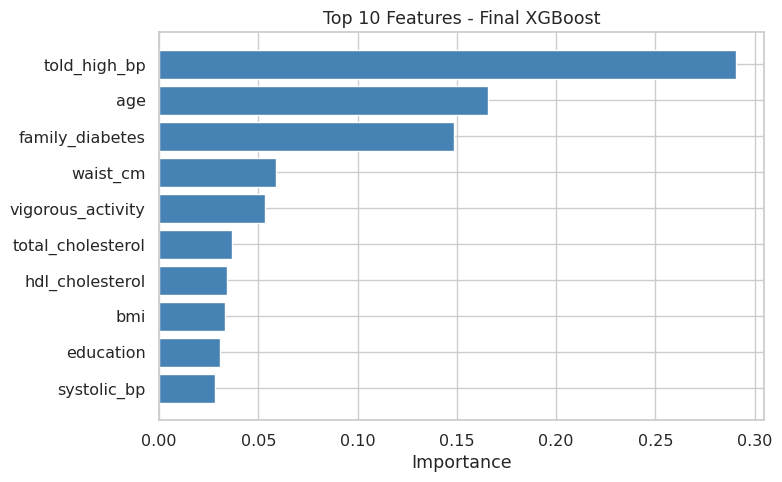

In [152]:
# 10. Feature importance chart - top 10 features of the final XGBoost model

pre = final_model.named_steps["preprocessor"]
model = final_model.named_steps["classifier"]
names = [n.split("__")[-1] for n in pre.get_feature_names_out()]

importance = pd.Series(model.feature_importances_, index=names).sort_values().tail(10)

plt.figure(figsize=(8, 5))
plt.barh(importance.index, importance.values, color="steelblue")
plt.xlabel("Importance")
plt.title("Top 10 Features - Final XGBoost")
plt.tight_layout()
plt.show()

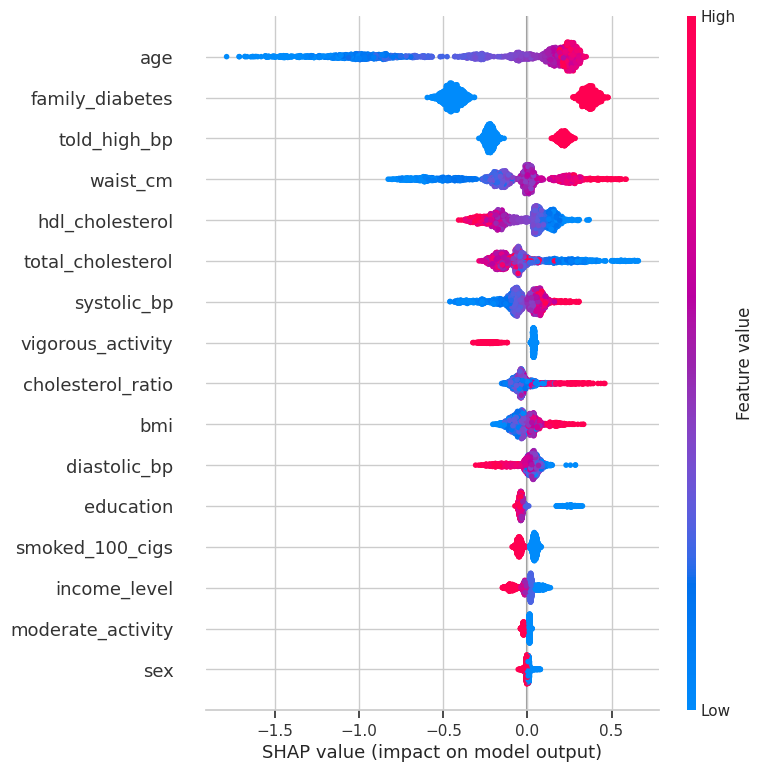

In [154]:

sample = X_train.sample(2000, random_state=42)
X_s = pre.transform(sample)

explainer = shap.TreeExplainer(model)
sv = explainer(X_s)

shap.summary_plot(sv.values[:, :, 2], X_s, feature_names=names)

## 13. Conclusions & Limitations

### Key findings

- A 3-class model (Normal, Prediabetes, Diabetes) was built on four NHANES cycles (2011-2018) using about 20,200 adults, with no glucose or HbA1c features.
- Six model types reached similar cross-validated ROC-AUC (0.76 to 0.78). Class weighting raised macro F1 for every model (about 3 points for the gradient-boosting models) and macro recall by 5 to 10 points, at the cost of about 4 points of accuracy, while ROC-AUC stayed the same.
- Tuning and stacking gave no meaningful gain, so the final model is the simpler tuned XGBoost.
- On the test set, the final model has an accuracy of about 0.60 and a macro F1 of about 0.56. Diabetes is found well (recall 0.70), Normal is found with high precision (0.84), and Prediabetes is the weakest class (precision 0.38, recall 0.46).
- Changing the decision threshold for Prediabetes did not help: precision rose only slightly while recall fell sharply, so the default rule was kept.

### Clinical relevance

The model is a screening aid, not a diagnosis. It could help flag people who should get a blood test, for example people with a larger waist, higher blood pressure, or a family history. Of the 697 people with diabetes in the test set, 52 were called Normal, and many Normal people were called Prediabetes, so a blood test is always needed.

### Limitations

- **Prediabetes ceiling.** The labels come from an HbA1c band, but the features contain no glycaemic measurement, so the model cannot see the line between Normal and Prediabetes. This is why all models stopped at the same level.
- **Label definition.** One HbA1c result decides the class, so people near a cutoff can be labeled differently by a small change. The Diabetes class also includes people already diagnosed by a doctor, who may be treated and may have changed their habits.
- **Limited features.** Physical activity covers only recreational activity. Diet, sleep, and medicines are not included, and several answers are self-reported.
- **Missing data.** About 10% of rows had missing numeric values and were filled with the median, and unreported income was filled with the most common level. Missingness was higher in the Diabetes class, so it may carry information.
- **Class imbalance.** Diabetes is only 17% of the data, so class weights were needed, and they trade precision for recall.
- **Evaluation.** Test confusion matrices of two early models were viewed before the final evaluation (no settings were chosen from them), model selection and tuning shared the same cross-validation folds, and results come from one train-test split without confidence intervals, so differences below about 0.01 are within noise.
- **Population and design.** The data are US adults from four cycles, are cross-sectional, and NHANES survey weights were not used, so the results may not apply to other populations.

## 14. Saving the Final Model

The final tuned XGBoost pipeline is saved as one file with `joblib`. The file includes the preprocessing (imputing, scaling, encoding) and the model, so new data goes in the same way as the training data. Missing values must be passed as `np.nan`, and the column names must match the training data. A reload test checks that the saved file gives the same predictions as the model in memory.

In [155]:
joblib.dump(final_model, "final_model.joblib")
files.download("final_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>